[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QML_NoisyIDS_ToNIoT_Cirillo2025.ipynb)

# QSVC, VQC and hybrid networks for intrusion detection on noisy simulated quantum computers: Cirillo and Esposito 2025 step by step

**Paper.** Franco Cirillo and Christian Esposito, *Quantum Machine Learning for Intrusion Detection on Noisy Quantum Computers*, 2025 IEEE International Conference on Quantum Computing and Engineering (QCE), pp. 1665 ff., 2025. DOI: [10.1109/QCE65121.2025.00184](https://doi.org/10.1109/QCE65121.2025.00184).

**What this notebook does.** It rebuilds the paper's study of three quantum classifiers, **Pegasos-QSVC** (a quantum-kernel support vector machine trained by stochastic gradient descent), the **VQC** (variational quantum classifier) and a **hybrid quantum-classical neural network**, on the **ToN_IoT** network-traffic dataset: first on an ideal simulator and then on *noisy* simulators built from three IBM device snapshots (`FakeNairobiV2`, `FakeLagosV2`, `FakePerth`). Every step has a plain-language explanation, a classical baseline (SVM, XGBoost, random forest, neural network) is trained on exactly the same inputs, and the notebook finishes with a table that puts its own numbers next to the paper's and gives a verdict per claim.

**How to run.** Google Colab, CPU runtime, *Runtime > Run all*. `FAST_MODE = True` (default) is a class demo; the run saved in this notebook took 39 minutes on a laptop CPU that was shared with other jobs (roughly half of that on an idle machine). `FAST_MODE = False` is the larger run described in the configuration cell: the full 378-configuration scan, the whole test split, noisy training of every Pegasos model, per-circuit kernel bandwidths, five optimisers, six hybrid networks. It needs several hours on a laptop CPU; every code path of it was executed here with tiny budgets as a smoke test, but the full run was **not completed**, so **all outputs saved in this notebook are those of the FAST run**. No account or token is needed: the dataset is downloaded from a public Hugging Face mirror inside the notebook (if you have a Hugging Face token, put it in Colab Secrets as `HF_TOKEN`; this data set does not require one, a gated dataset would).

**What you get at the end.** Real-data plots of the ten traffic classes, drawings of the circuits that are really executed, accuracy/F1 tables for ideal and noisy simulation of all three models, the paper's regularisation, step, qubit, repetition, feature-map, ansatz and optimiser studies in reduced form, and an honest verdict on which claims of the paper this reproduction supports.

**Scope and relation to other notebooks.** This is the **conference version**: ToN_IoT only, hardware never used (the authors ran fake backends only). The same authors' journal extension (same models, plus NSL-KDD) is the notebook `QML_NoisyIDSBenchmark_Cirillo2026.ipynb` in this folder; this notebook follows the conference text, in particular its preprocessing (duplicates eliminated, which reproduces the paper's 74.56 % all-attack accuracy), its hybrid architecture (Fig. 7) and its table structure (Tables II, III, X to XVII).

## The paper in one page

**Problem.** Intrusion detection (is a network connection normal or an attack?) with quantum machine learning (QML) on *noisy* (NISQ) hardware. The authors do not claim to beat classical models; they want to know which circuit structures survive device noise, and give design rules.

**Decision.** Binary: normal (0) versus attack (1); attack is the positive class (a model that says "attack" for every row has recall 100 %).

**Data.** The **ToN_IoT** network file (UNSW Canberra), 211,043 flows of normal traffic and nine attack types. Preprocessing: remove irrelevant features, handle missing values, eliminate duplicates, encode categorical data, split into train and test, min-max scaling, **PCA to as many components as qubits**.

**Models.**
1. **Pegasos-QSVC.** Regularisation `C` from 0.01 to 1000 (Table II: `C=1000` chosen), 20 to 500 Pegasos steps (100 chosen); 14 feature maps (`ZFeatureMap`, `ZZFeatureMap` with linear / full / circular entanglement, `PauliFeatureMap` with 10 Pauli strings), 1 to 3 repetitions, 2 to 10 qubits: 378 configurations, best ones in Table III, tested on `FakeNairobiV2`, `FakeLagosV2`, `FakePerth` in Table X. Headline: 5 qubits, `ZFeatureMap`, r=1, accuracy 93.05 %, F1 93.73 % under noise.
2. **VQC.** The same 14 feature maps (1 repetition) combined with `RealAmplitudes`, `EfficientSU2`, `TwoLocal`, `PauliTwoDesign` (1 to 3 repetitions, 2 to 8 qubits, 1,176 runs, COBYLA with 50 iterations); optimiser study with COBYLA / SPSA / NFT / Nelder-Mead / Powell (200 iterations, Table XII); noisy runs in Table XIII (best: 3 qubits, `Pauli[Y]`, `RealAmplitudes`, r=2, 91.57 % accuracy).
3. **Hybrid network.** Linear layers (64 units), ReLU, a Qiskit `EstimatorQNN` (feature map + ansatz) as hidden layer, Adam (Fig. 7, Tables XIV and XV); best 5 qubits, `Pauli[ZY]`, `EfficientSU2`, r=1: 95.4 % ideal, 94.2 % on `FakePerth`.

**Noise.** Fake IBM backends (calibration snapshot of 2024-05-27) with 7 qubits and the same coupling map but different error levels: FakeLagos has the worst CNOT and readout errors, FakeNairobi and FakePerth have worse single-qubit gates but better CNOTs and readout.

**Claims that can be checked here.**
* Table II: Pegasos-QSVC needs a large `C` (92.25 % at `C=1000`, collapsing to "everything is an attack", 74.56 %, for `C <= 1`).
* Table III / X: best ideal accuracies 93 to 95.6 %; under noise 74.6 to 93.1 % depending on circuit and backend (some circuits collapse completely).
* Section IV: accuracy rises with qubits and saturates at 6 to 7; `ZZ` full/circular better than linear at low repetitions; `Z,YY` consistently good; `EfficientSU2` is the best ansatz and `PauliTwoDesign` the worst; COBYLA is usually the best optimiser.
* Tables XII to XVII: VQC 81 to 94 % depending on optimiser, 91.6 % noisy; hybrid network 95.4 % ideal and 86.8 / 90.0 / 94.2 % on Lagos / Nairobi / Perth.
* Qualitative: noise lowers accuracy; FakeLagos is the most sensitive backend for CNOT-heavy circuits; Pegasos-QSVC with 5 qubits beats the previous state of the art under noise (93.05 % vs 89.7 %).
* The timing statements are not reproducible in absolute terms (different hardware and budgets).

### What follows the paper and what had to be chosen

The paper leaves many details open (cleaning details, the exact feature scaling, split ratio, hybrid network sizes, how the hybrid network was trained under noise). Everything not stated is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data file | ToN_IoT, 211,043 flows | same `Train_Test_Network` file from the public Hugging Face mirror `codymlewis/TON_IoT_network` (identical class counts to the paper's) |
| Cleaning | irrelevant features removed, missing values handled, duplicates eliminated, categorical encoding | IP addresses and ports dropped, **duplicate rows removed** (93,925 rows remain; their attack share 74.53 % matches the 74.56 % that the paper's collapsed models in Table II score, whereas the raw file gives 76.3 %), text columns become integer codes (`# CHOICE`), missing values -> 0, constant columns dropped |
| Split | train / test, ratio not stated | stratified 80/20 by the ten real classes (`# CHOICE`) |
| Scaling + PCA | "min-max scaling, then PCA" | signed log1p -> StandardScaler -> PCA(n_qubits) -> clip to the training 1st-99th percentile -> MinMaxScaler((0, a_max)), all fitted on the training split only; `a_max` (the kernel bandwidth) tuned on a validation split of the training data: one global value in `FAST_MODE`, one per circuit in the large run (`# CHOICE`) |
| Pegasos-QSVC | `C=1000`, 100 steps, Qiskit 1.1 / ML 0.7 | same; ideal kernel computed exactly from statevectors, noisy kernel from `P(0...0)` of the compute-uncompute circuit on a noisy Aer simulator with 1024 shots; Pegasos draws its ~100 rows from a stratified pool of the training split (`PEGASOS_POOL`; statistically equivalent, much cheaper to simulate) |
| Circuit for Table II | not stated | 5-qubit `ZFeatureMap` r=1, the headline circuit (`# CHOICE`) |
| Pauli feature-map entanglement | not stated | Qiskit default (`full`) |
| 378-configuration scan | all 2-10 qubits, 14 maps, 1-3 reps | full grid in the large run (on a test subset), a thin slice in `FAST_MODE` |
| VQC | 1,176 runs, whole training set, COBYLA 50 / 200 iterations | same Qiskit `VQC` class, ansatz and optimisers, **much smaller** training budgets (see the configuration cell); noisy runs train on the noisy simulator (`VQC(sampler=AerSampler(noise_model), pass_manager=<preset for the fake backend>)`) |
| `TwoLocal`, `PauliTwoDesign` | RY + CX; RY(pi/4) start | Qiskit `n_local(ry, cx)` and `pauli_two_design` with a fixed seed |
| Hybrid network | n_features -> 64 -> 64 -> n_qubits -> `EstimatorQNN` -> output, Adam | same layers on the full standardised feature vector; loss, learning rate, epochs, batch size and output observable are not stated: target `2y-1`, MSE loss, class = sign of `<Z...Z>` (`# CHOICE`) |
| Hybrid quantum layer | `EstimatorQNN` + `TorchConnector` (parameter-shift) | a batched Aer layer with finite-difference gradients, **checked equal** to `EstimatorQNN` forward and backward (Section 5); parameter-shift through the Estimator primitive takes about 30 s per 64-sample step here |
| Hybrid noisy runs | not stated how trained | trained ideally, then **evaluated** on the noisy simulators (training under noise is too slow here) |
| Noisy Pegasos-QSVC | trained and evaluated on the noisy simulators | large run: trained and evaluated with the noisy kernel; `FAST_MODE`: the 100 Pegasos steps use the exact kernel (a noisy training costs about 1,000 extra circuit runs per model) and only the prediction runs on the noisy device kernel (`NOISY_TRAINING`) |
| Noisy evaluation | whole test set | stratified test subsets (30 to 60 rows) because every noisy kernel entry is a circuit run; verdicts say "within sampling error" when the gap is inside the binomial interval |
| Classical baselines | none in the paper | SVM(rbf), XGBoost, random forest, MLP on identical PCA inputs, and on all features |
| Repeats and seeds | one run per configuration, seed not stated | Pegasos draws its training rows at random, so the ideal Pegasos runs are repeated over five model seeds (`PEGASOS_SEEDS`, same data split) and reported as mean +- std; the other models use one seed (`SEEDS`) |
| Test rows | whole test split | whole test split (18,785 rows) in the large run; a stratified 4,000-row subset for the ideal Pegasos runs in `FAST_MODE` |

## 1. Setup

The first cell installs pinned, tested versions (it does nothing locally if they are already importable). On Colab a *session restart* may be requested after the install; if so, run all cells again.

In [1]:
import importlib.util, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    return importlib.util.find_spec(m) is not None
if IN_COLAB or not all(_have(m) for m in ["qiskit", "qiskit_machine_learning", "qiskit_aer", "qiskit_ibm_runtime", "torch"]):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-machine-learning==0.9.1",
                    "qiskit-aer==0.17.2", "qiskit-ibm-runtime==0.50.0", "pylatexenc", "xgboost", "huggingface_hub"], check=False)
    print("installed pinned versions; if Colab asks for a restart, restart and run all cells again")
else:
    print("pinned libraries already importable; nothing to install")

pinned libraries already importable; nothing to install


### 1.1 Configuration

Every tunable constant is here. `FAST_MODE = True` is a class demo with small budgets; `FAST_MODE = False` is the larger run (documented in the comments of the cell and in the "What follows the paper" table). The paper's own budgets (378 Pegasos-QSVC configurations, 1,176 VQC configurations, noisy runs on the whole test set, hybrid networks trained for many hours) are far beyond a notebook; the reduced budgets are listed explicitly.

In [2]:
import math
FAST_MODE = True            # True: demo (about 10-15 min on a laptop CPU). False: larger run (see the budgets below)
SEED = 42                   # global seed (data checks, torch init); per-run seeds come from SEEDS
DATA_DIR = "data"           # downloads are cached here (about 30 MB)
IBM_TOKEN = ""              # optional: a token for IBM Quantum enables the one real-hardware cell in Section 7; the paper itself reports no hardware run
SHOTS = 1024                # shots of every sampled quantity (kernel entries, VQC outputs, <Z..Z> of the hybrid layer)
TOL = 2.0                   # a numeric claim is "reproduced" when within 2 accuracy points (0.02 F1)
TEST_FRAC = 0.2             # paper: train/test split (ratio not stated; 80/20 as in the same authors' other papers)
AMAX_GRID = [math.pi / 2, math.pi, 2 * math.pi]   # CHOICE: candidate kernel bandwidths (angle range of the final MinMax scaling)
BACKENDS_ALL = ["FakeNairobiV2", "FakeLagosV2", "FakePerth"]     # the three 7-qubit snapshots of the paper (2024-05-27 calibration data)
HQNN_HIDDEN = 64            # paper Fig. 7: two hidden layers of 64 units
NOISY_TRAINING = not FAST_MODE        # True: the noisy Pegasos runs are trained AND evaluated with the noisy kernel (as in the paper); False: trained with the exact kernel, evaluated noisy
PER_CIRCUIT_AMAX = not FAST_MODE   # True: every Pegasos-QSVC circuit gets its own kernel bandwidth tuned on a validation split (large run); False: one global bandwidth (FAST)
PEGASOS_SEEDS = [1, 2, 3, 4, 5]    # Pegasos draws its training rows at random: the ideal runs are repeated over these model seeds (same data split)

if FAST_MODE:
    SEEDS = [12345]                                   # paper: seed not stated
    N_SVC_TRAIN, N_CLASSICAL_TRAIN = 3000, 8000      # SVC(rbf) / the other classical baselines train on this many training rows (kernel SVM is quadratic in n)
    CLASSICAL_Q = [3, 5, 7]
    C_SWEEP = [1000, 100, 10, 1]                      # paper Table II: 1000 ... 0.01
    STEPS_SWEEP = [20, 100]                           # paper: 20, 50, 100, 200, 500
    SCAN_QUBITS, SCAN_REPS = [3, 5, 7], [1, 2]        # paper: 2-10 qubits, reps 1-3
    SCAN_MAPS = ["Z", "ZZ-linear", "ZZ-full", "Z,YY", "Y"]       # paper: 14 feature maps
    SCAN_TEST = 2000
    PEGASOS_POOL, SCAN_POOL = 3000, 1000                # Pegasos draws its ~100 training rows from a stratified pool of this many training rows (its cost does not depend on the pool size)
    IDEAL_N_TEST = 4000                               # test rows of the ideal Pegasos runs (None = the whole test split, 18,785 rows)
    QSVC_NOISELESS = ["ZZlin6r1", "PZX6r1", "ZYY4r1", "Z7r2", "PXX5r2", "PZXX6r2", "PZYZZ4r2", "ZZlin5r3"]   # paper Table III: all 8
    QSVC_NOISY = ["Z5r1", "ZYY4r1"]                   # paper Table X has 8 configurations (the CNOT-heavy ones cost minutes per noisy run)
    NOISY_BACKENDS = BACKENDS_ALL
    NOISY_STEPS, NOISY_N_TEST = 100, 40                # noisy kernel entries are separate circuit runs: about 1000x the cost of the exact kernel
    VQC_TRAIN, VQC_TEST, VQC_ITERS = 60, 300, 30      # paper: whole training set, 50 (maps) / 200 (optimisers) iterations
    VQC_SCAN_MAPS, VQC_SCAN_REPS, VQC_SCAN_TRAIN, VQC_SCAN_ITERS = ["Y"], [1, 3], 30, 6
    VQC_OPT_CFGS = ["PY3"]                            # paper Table XII has 6 circuits x 5 optimisers
    VQC_OPTIMIZERS = ["COBYLA", "NELDER_MEAD"]
    VQC_NOISY_RUNS = [("PY3", "COBYLA")]              # (circuit, optimiser); paper Table XIII has 5 circuit/optimiser pairs
    VQC_NOISY_TEST = 40
    HQNN_CFGS = ["HZY5"]                              # paper Table XIV has 9 configurations
    HQNN_TRAIN, HQNN_TEST, HQNN_EPOCHS, HQNN_BATCH, HQNN_LR = 128, 400, 4, 16, 0.01
    HQNN_NOISY_TEST = 40
else:
    SEEDS = [12345]
    N_SVC_TRAIN, N_CLASSICAL_TRAIN = 15000, 40000
    CLASSICAL_Q = [2, 3, 4, 5, 6, 7, 8, 9, 10]
    C_SWEEP = [1000, 100, 10, 1, 0.1, 0.01]
    STEPS_SWEEP = [20, 50, 100, 200, 500]
    SCAN_QUBITS, SCAN_REPS = list(range(2, 11)), [1, 2, 3]
    SCAN_MAPS = ["Z", "ZZ-linear", "ZZ-full", "ZZ-circular", "X", "Y", "XX", "XZ", "ZX", "YZ", "ZY", "Z,YY", "Z,XX", "Z,Y,ZZ"]   # the paper's 14 maps -> 378 configurations
    SCAN_TEST = 3000
    PEGASOS_POOL, SCAN_POOL = 20000, 3000
    IDEAL_N_TEST = None
    QSVC_NOISELESS = ["ZZlin6r1", "PZX6r1", "ZYY4r1", "Z7r2", "PXX5r2", "PZXX6r2", "PZYZZ4r2", "ZZlin5r3"]
    QSVC_NOISY = ["PZX6r1", "ZYY4r1", "Z5r1", "Z7r2", "PXX5r2", "PZXX6r2", "ZZlin5r3", "PZYZZ4r3"]       # paper Table X: all 8 rows
    NOISY_BACKENDS = BACKENDS_ALL
    NOISY_STEPS, NOISY_N_TEST = 100, 60
    VQC_TRAIN, VQC_TEST, VQC_ITERS = 150, 600, 50
    VQC_SCAN_MAPS, VQC_SCAN_REPS, VQC_SCAN_TRAIN, VQC_SCAN_ITERS = ["Y", "ZZ-linear", "ZZ-circular", "Z,YY"], [1, 2, 3], 80, 20
    VQC_OPT_CFGS = ["PY3", "ZZc3"]
    VQC_OPTIMIZERS = ["COBYLA", "SPSA", "NFT", "NELDER_MEAD", "POWELL"]
    VQC_NOISY_RUNS = [("PY3", "COBYLA"), ("PY3", "SPSA"), ("ZZ3", "COBYLA"), ("ZYY5", "SPSA"), ("ZZc3", "NELDER_MEAD")]
    VQC_NOISY_TEST = 60
    HQNN_CFGS = ["HZY5", "HYZ3", "HZYY3"]
    HQNN_TRAIN, HQNN_TEST, HQNN_EPOCHS, HQNN_BATCH, HQNN_LR = 256, 800, 6, 16, 0.01
    HQNN_NOISY_TEST = 60
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "| noisy backends:", NOISY_BACKENDS)

FAST_MODE = True | seeds: [12345] | noisy backends: ['FakeNairobiV2', 'FakeLagosV2', 'FakePerth']


In [3]:
import os, time, shutil, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests, torch
warnings.filterwarnings("ignore")
import qiskit, qiskit_aer, qiskit_machine_learning, qiskit_ibm_runtime
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter
from qiskit.circuit.library import z_feature_map, zz_feature_map, pauli_feature_map, real_amplitudes, efficient_su2, n_local, pauli_two_design
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit_ibm_runtime.fake_provider import FakeLagosV2, FakeNairobiV2, FakePerth
from qiskit_machine_learning.algorithms import VQC, PegasosQSVC
from qiskit_machine_learning.kernels import BaseKernel, FidelityStatevectorKernel
from qiskit_machine_learning.optimizers import COBYLA, SPSA, NFT, NELDER_MEAD, POWELL
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.utils import algorithm_globals
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score
from xgboost import XGBClassifier
from IPython.display import display

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
print("qiskit", qiskit.__version__, "| aer", qiskit_aer.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| ibm-runtime", qiskit_ibm_runtime.__version__, "| torch", torch.__version__)
FAKE = {"FakeNairobiV2": FakeNairobiV2(), "FakeLagosV2": FakeLagosV2(), "FakePerth": FakePerth()}
for k, b in FAKE.items():
    print(k, "qubits:", b.num_qubits, "| coupling edges:", len(b.coupling_map.get_edges()) // 2)

qiskit 2.5.2 | aer 0.17.2 | qiskit-machine-learning 0.9.1 | ibm-runtime 0.50.0 | torch 2.14.1+cpu
FakeNairobiV2 qubits: 7 | coupling edges: 6
FakeLagosV2 qubits: 7 | coupling edges: 6
FakePerth qubits: 7 | coupling edges: 6


### 1.2 Helper library: data, preprocessing, metrics

* `load_ton` downloads the ToN_IoT **network** file (`Train_Test_Network`, 211,043 rows, 44 columns) from the public Hugging Face mirror, drops the identifier columns (IP addresses, ports), removes **duplicate rows** (the paper lists "eliminating duplicates"), turns text columns into integer codes and drops constant columns.
* `make_split` is the stratified 80/20 split (stratified by the ten real classes: normal plus nine attack types); `take` draws stratified subsets for the expensive quantum runs.
* `prep` is the preprocessing of the quantum models: signed `log1p` (byte and packet counts are heavy-tailed), `StandardScaler`, `PCA(n_components = qubits)`, clipping to the training 1st-99th percentile, and `MinMaxScaler((0, a_max))`. **Everything is fitted on the training rows only**; test angles are clipped to the training range.
* All metrics treat *attack* (label 1) as the positive class, as the paper does (its collapsed models have recall 100 %).

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
# The Hugging Face mirror used below is public: the token is only passed on if the reader has one (no gated data here).

def load_ton():
    path = os.path.join(DATA_DIR, "train_test_network.csv")
    if not os.path.exists(path):
        from huggingface_hub import hf_hub_download
        try:
            hf_hub_download("codymlewis/TON_IoT_network", "train_test_network.csv", repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
        except Exception as e:
            print("primary mirror failed:", repr(e)[:120], "-> zip mirror")
            zp = hf_hub_download("m-hesam-moradian/ToN_IoT_Train_Test_datasets", "Train_Test_datasets.zip", repo_type="dataset",
                                 local_dir=DATA_DIR, token=HF_TOKEN)
            with zipfile.ZipFile(zp) as z:
                member = [n for n in z.namelist() if n.lower().endswith("train_test_network.csv")][0]
                with z.open(member) as src, open(path, "wb") as dst:
                    shutil.copyfileobj(src, dst)
            os.remove(zp)                                            # do not keep the large archive
    raw0 = pd.read_csv(path, low_memory=False)
    raw = raw0.drop(columns=["src_ip", "dst_ip", "src_port", "dst_port"])          # CHOICE: identifiers and ports are "irrelevant features"
    raw = raw.drop_duplicates().reset_index(drop=True)                             # paper Section III-A: duplicates eliminated
    y = raw["label"].values.astype(int)
    fam = raw["type"].astype(str).values
    X = raw.drop(columns=["label", "type"]).copy()
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].astype("category").cat.codes                  # CHOICE: integer codes for text columns (categorical encoding)
    X = X.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0)       # missing values -> 0
    X = X.loc[:, X.nunique() > 1]
    return dict(raw0_shape=raw0.shape, raw=raw, X=X, y=y, fam=fam)

def make_split(seed):
    """Stratified (by the ten real classes) 80/20 split. Returns row positions into DATA['X']."""
    fam = DATA["fam"]; idx = np.arange(len(fam))
    return train_test_split(idx, test_size=TEST_FRAC, stratify=fam, random_state=seed)

def take(idx, y, n, seed):
    """Stratified (by label) random subset of at most n rows of idx."""
    if n is None or n >= len(idx):
        return idx
    sub, _ = train_test_split(idx, train_size=n, stratify=y[idx], random_state=seed)
    return sub

def signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))

_PCA_FIT = {}
def pca_coords(tr, te, q):
    """signed log1p -> StandardScaler -> PCA(q); fitted on the training rows only (fit cached per training split). Returns the raw PCA coordinates of the train and test rows."""
    X = DATA["X"].values.astype(float)
    key = (len(tr), int(tr[0]), int(tr[-1]), q)
    if key not in _PCA_FIT:
        A = signed_log(X[tr])                                  # CHOICE: byte/packet counts are heavy-tailed, the log keeps outliers from dominating the PCA
        sc = StandardScaler().fit(A)
        pca = PCA(n_components=q, random_state=SEED).fit(sc.transform(A))
        _PCA_FIT[key] = (sc, pca, pca.transform(sc.transform(A)))
    sc, pca, Ptr = _PCA_FIT[key]
    return Ptr, pca.transform(sc.transform(signed_log(X[te])))
def prep(tr, te, q, amax=math.pi):
    """signed log1p -> StandardScaler -> PCA(q) -> clip to the training 1st-99th percentile -> MinMax((0, amax)); fitted on the training rows only."""
    Ptr, Pte = pca_coords(tr, te, q)
    lo, hi = np.percentile(Ptr, [1, 99], axis=0)           # CHOICE: tails clipped so that a few extreme flows do not squeeze everybody else into a tiny angle range
    Ptr, Pte = np.clip(Ptr, lo, hi), np.clip(Pte, lo, hi)
    mm = MinMaxScaler((0, amax)).fit(Ptr)
    return np.clip(mm.transform(Ptr), 0, amax), np.clip(mm.transform(Pte), 0, amax)

def prep_full(tr, te):
    """All numeric features, signed log1p -> StandardScaler (training rows only) -> clipped to +-5: the input of the hybrid network (paper Fig. 7: n_features -> 64 -> 64 -> n_qubits)."""
    X = DATA["X"].values.astype(float)
    A, B = signed_log(X[tr]), signed_log(X[te])
    sc = StandardScaler().fit(A)
    return np.clip(sc.transform(A), -5, 5), np.clip(sc.transform(B), -5, 5)

def metrics(y_true, y_pred):
    return dict(acc=100 * accuracy_score(y_true, y_pred),
                prec=100 * precision_score(y_true, y_pred, zero_division=0),
                rec=100 * recall_score(y_true, y_pred, zero_division=0),
                f1=100 * f1_score(y_true, y_pred, zero_division=0),
                bacc=100 * balanced_accuracy_score(y_true, y_pred))

RES = []                                  # every result row of the notebook ends up here
def log(**kw):
    RES.append(kw); return kw

DATA = load_ton()
print(f"ToN_IoT network file: raw {DATA['raw0_shape']} -> after dropping IPs/ports and duplicates {DATA['raw'].shape} -> {DATA['X'].shape[1]} numeric model features; "
      f"attack share {DATA['y'].mean():.4f}")

ToN_IoT network file: raw (211043, 44) -> after dropping IPs/ports and duplicates (93925, 40) -> 38 numeric model features; attack share 0.7453


### 1.3 Helper library: feature maps, kernels, ansatz and noisy simulators

* `feature_map(name, q, reps)` builds the paper's 14 maps with Qiskit's function-style circuit library. `Z` is `ZFeatureMap`; `ZZ-linear/full/circular` is `ZZFeatureMap`; every other name is a `PauliFeatureMap` with the comma-separated Pauli strings (Qiskit default `full` entanglement for the Pauli maps, `# CHOICE`, the paper does not say).
* `BatchedStatevectorKernel` is the **ideal** kernel `|<phi(x)|phi(y)>|^2`; its statevectors are produced by Aer in batches and cached. It is checked against Qiskit's `FidelityStatevectorKernel` and against a hand computation in Section 3.1.
* `NoisyFidelityKernel` is the **noisy** kernel: the compute-uncompute circuit `U(y)^dagger U(x)` is transpiled once for the fake device (basis gates and coupling map included), and `P(0...0)` is estimated from 1024 shots on an Aer density-matrix simulator that carries the device's full noise model (gate errors, thermal relaxation, readout error). This is the same quantity that a `FidelityQuantumKernel` with a noisy sampler estimates.
* `BatchPegasos` is Qiskit's `PegasosQSVC` with a batched `decision_function` (identical maths, one kernel call for the whole test set instead of one per sample).

In [5]:
def feature_map(name, q, reps):
    if name == "Z":
        return z_feature_map(q, reps=reps)
    if name.startswith("ZZ-"):
        return zz_feature_map(q, reps=reps, entanglement=name.split("-")[1])
    return pauli_feature_map(q, reps=reps, paulis=name.split(","))       # CHOICE: default entanglement ("full")

def build_ansatz(name, q, reps):
    if name == "TwoLocal":                                               # paper Fig. 1: RY rotations + CX entanglement (Qiskit's TwoLocal)
        return n_local(q, rotation_blocks="ry", entanglement_blocks="cx", reps=reps)
    if name == "PauliTwoDesign":                                         # paper Fig. 2: initial RY(pi/4), then random single-qubit Paulis + CZ layers
        return pauli_two_design(q, reps=reps, seed=SEED)
    return {"RealAmplitudes": real_amplitudes, "EfficientSU2": efficient_su2}[name](q, reps=reps)

class BatchedStatevectorKernel(BaseKernel):
    """Exact fidelity kernel; Aer returns many statevectors per call and they are cached by input row."""
    def __init__(self, fm):
        super().__init__(feature_map=fm, enforce_psd=False)
        qc = fm.copy(); qc.save_statevector()
        self.executed = qc                                            # the circuit that is really simulated
        self._sim = AerSimulator(method="statevector"); self._params = list(fm.parameters); self._cache = {}
    def _states(self, X):
        X = np.atleast_2d(np.asarray(X, dtype=float)); keys = [r.tobytes() for r in X]
        todo, seen = [], set()
        for i, k in enumerate(keys):
            if k not in self._cache and k not in seen:
                seen.add(k); todo.append(i)
        for s in range(0, len(todo), 256):
            ch = todo[s:s + 256]
            binds = {p: [float(X[i, j]) for i in ch] for j, p in enumerate(self._params)}
            res = self._sim.run(self.executed, parameter_binds=[binds]).result()
            for pos, i in enumerate(ch):
                self._cache[keys[i]] = np.asarray(res.data(pos)["statevector"])
        return np.array([self._cache[k] for k in keys])
    def evaluate(self, x_vec, y_vec=None):
        a = self._states(x_vec)
        if y_vec is not None and np.size(y_vec) == 0:
            return np.zeros((len(a), 0))
        b = a if y_vec is None else self._states(y_vec)
        return np.abs(a.conj() @ b.T) ** 2

_NOISE_SIMS = {}
def noisy_simulator(backend_name):
    if backend_name not in _NOISE_SIMS:
        _NOISE_SIMS[backend_name] = AerSimulator(noise_model=NoiseModel.from_backend(FAKE[backend_name]), method="density_matrix")
    return _NOISE_SIMS[backend_name]

class NoisyFidelityKernel(BaseKernel):
    """|<phi(x)|phi(y)>|^2 estimated as P(0...0) of U(x) followed by U(y)^dagger on a noisy Aer simulator (1024 shots)."""
    def __init__(self, fm, backend_name, shots=SHOTS, seed=SEED):
        super().__init__(feature_map=fm, enforce_psd=False)
        n = fm.num_qubits
        a = [Parameter(f"a{i:02d}") for i in range(n)]; b = [Parameter(f"b{i:02d}") for i in range(n)]
        circ = fm.assign_parameters(dict(zip(fm.parameters, a))).compose(fm.assign_parameters(dict(zip(fm.parameters, b))).inverse())
        circ.measure_all()
        self.logical = circ
        self.executed = transpile(circ, FAKE[backend_name], optimization_level=1, seed_transpiler=seed)   # coupling map + basis gates
        self.sim, self.shots, self.seed, self.n = noisy_simulator(backend_name), shots, seed, n
        self.cx = self.executed.count_ops().get("cx", 0); self.depth = self.executed.depth()
    def evaluate(self, x_vec, y_vec=None):
        x_vec = np.atleast_2d(x_vec); y_vec = x_vec if y_vec is None else np.atleast_2d(y_vec)
        if y_vec.size == 0:
            return np.zeros((len(x_vec), 0))
        vals = np.concatenate([np.repeat(x_vec, len(y_vec), axis=0), np.tile(y_vec, (len(x_vec), 1))], axis=1)
        names = [f"a{i:02d}" for i in range(self.n)] + [f"b{i:02d}" for i in range(self.n)]
        binds = {p: vals[:, names.index(p.name)].tolist() for p in self.executed.parameters}
        res = self.sim.run(self.executed, parameter_binds=[binds], shots=self.shots, seed_simulator=self.seed).result()
        zero = "0" * self.n
        return np.array([res.get_counts(i).get(zero, 0) / self.shots for i in range(len(vals))]).reshape(len(x_vec), len(y_vec))

class BatchPegasos(PegasosQSVC):
    """PegasosQSVC with a batched decision function (same formula as the parent, one kernel call for all test rows)."""
    def decision_function(self, X):
        X = np.atleast_2d(X); sup = list(self._alphas.keys())
        K = self._quantum_kernel.evaluate(X, self._x_train[sup]) + self._kernel_offset
        yv = np.array([self._label_map[v] for v in self._y_train[sup]]); al = np.array(list(self._alphas.values()))
        return K @ (al * yv)
print("kernels ready")

kernels ready


### 1.4 Paper configurations and paper values

The `key` of each configuration is used throughout. The paper values are copied from the tables of the paper: Table II (regularisation `C`), Table III (best ideal Pegasos-QSVC), Table X (noisy Pegasos-QSVC), Tables XI and XII (VQC), Table XIII (noisy VQC), Tables XIV and XV (hybrid network), Tables XVI and XVII (summaries). Every value is `(accuracy, F1)` in percent unless stated.

In [6]:
# ---- Pegasos-QSVC configurations: feature map name, qubits, repetitions -------------------------------------------------------
# paper Table III (ideal): (acc, precision, recall, F1, balanced acc)
QSVC_CFG = {
    "ZZlin6r1": dict(label="q=6 ZZ(Linear) r=1",     fm="ZZ-linear", q=6, r=1, ideal=(94.12, 96.10, 96.01, 96.05, 92.29)),
    "PZX6r1":   dict(label="q=6 Pauli[ZX] r=1",      fm="ZX",        q=6, r=1, ideal=(94.16, 96.04, 96.13, 96.09, 92.26)),
    "ZYY4r1":   dict(label="q=4 Pauli[Z,YY] r=1",    fm="Z,YY",      q=4, r=1, ideal=(93.17, 93.91, 97.15, 95.50, 89.34)),
    "Z7r2":     dict(label="q=7 ZFeatureMap r=2",    fm="Z",         q=7, r=2, ideal=(95.44, 96.93, 96.96, 96.94, 93.98)),
    "PXX5r2":   dict(label="q=5 Pauli[XX] r=2",      fm="XX",        q=5, r=2, ideal=(94.14, 96.22, 95.91, 96.06, 92.43)),
    "PZXX6r2":  dict(label="q=6 Pauli[Z,XX] r=2",    fm="Z,XX",      q=6, r=2, ideal=(95.61, 97.11, 96.99, 97.05, 94.27)),
    "PZYZZ4r2": dict(label="q=4 Pauli[Z,Y,ZZ] r=2",  fm="Z,Y,ZZ",    q=4, r=2, ideal=(94.57, 95.89, 96.86, 96.37, 92.35)),
    "ZZlin5r3": dict(label="q=5 ZZ(Linear) r=3",     fm="ZZ-linear", q=5, r=3, ideal=(94.35, 95.65, 96.83, 96.24, 91.96)),
    # two circuits that appear only in the noisy table (Table X); they have no ideal row in Table III
    "Z5r1":     dict(label="q=5 ZFeatureMap r=1",    fm="Z",         q=5, r=1, ideal=None),
    "PZYZZ4r3": dict(label="q=4 Pauli[Z,Y,ZZ] r=3",  fm="Z,Y,ZZ",    q=4, r=3, ideal=None),
}
# paper Table X (noisy, FakeNairobi / FakeLagos / FakePerth): (acc, precision, recall, F1, balanced acc)
_c = (74.56, 74.56, 100.0, 85.42, 50.00); _b = (83.25, 86.42, 91.98, 89.12, 74.82); _z5 = (93.05, 95.43, 97.18, 93.73, 89.07)
QSVC_NOISY_PAPER = {
    "PZX6r1":   {"FakeNairobiV2": (93.03, 95.42, 97.17, 93.71, 89.05), "FakeLagosV2": (88.10, 93.31, 90.62, 91.95, 85.79), "FakePerth": (88.10, 93.31, 90.62, 91.95, 85.79)},
    "ZYY4r1":   {"FakeNairobiV2": _b, "FakeLagosV2": (91.07, 91.44, 97.12, 94.19, 85.23), "FakePerth": (91.54, 91.99, 97.15, 94.50, 86.18)},
    "Z5r1":     {"FakeNairobiV2": _z5, "FakeLagosV2": _z5, "FakePerth": _z5},
    "Z7r2":     {"FakeNairobiV2": (82.37, 92.28, 83.33, 87.58, 81.45), "FakeLagosV2": (90.43, 90.23, 97.75, 93.84, 83.37), "FakePerth": (82.37, 92.28, 83.33, 87.58, 81.45)},
    "PXX5r2":   {"FakeNairobiV2": (91.28, 91.69, 97.15, 94.34, 85.67), "FakeLagosV2": (89.84, 96.23, 89.89, 92.96, 89.79), "FakePerth": (82.42, 91.02, 84.79, 87.80, 80.14)},
    "PZXX6r2":  {"FakeNairobiV2": _c, "FakeLagosV2": _c, "FakePerth": _c},
    "ZZlin5r3": {"FakeNairobiV2": _b, "FakeLagosV2": (92.11, 94.83, 97.08, 92.68, 87.31), "FakePerth": _b},
    "PZYZZ4r3": {"FakeNairobiV2": _b, "FakeLagosV2": _b, "FakePerth": _b},
}
def hm(a, b):
    return 2 * a * b / (a + b)
def corrected_f1(v):
    """v = (acc, precision, recall, F1, balanced acc) as printed in Table X. Returns (F1 to compare with, note). In three rows of Table X the printed precision and F1
    are interchanged: the harmonic mean of the printed F1 and recall equals the printed precision (and the accuracy/balanced accuracy only fit the swapped values)."""
    acc, p, r, f, ba = v
    if abs(hm(p, r) - f) <= 0.15:
        return f, "as printed"
    if abs(hm(f, r) - p) <= 0.15:
        return p, "printed precision and F1 interchanged"
    return f, "printed F1 inconsistent with precision and recall"
# paper Table II (C sweep): C -> (acc, precision, recall, F1). The circuit is not stated.
TABLE2 = {1000: (92.25, 92.77, 97.18, 94.92), 100: (91.61, 92.02, 97.18, 94.53), 10: (79.16, 89.48, 81.65, 85.39),
          1: (74.56, 74.56, 100.0, 85.42), 0.1: (74.56, 74.56, 100.0, 85.42), 0.01: (74.56, 74.56, 100.0, 85.42)}
TABLE2_CIRCUIT = "Z5r1"      # CHOICE: the paper does not say which circuit Table II belongs to; the headline 5-qubit ZFeatureMap (r=1) is used

# ---- VQC configurations (feature map reps = 1 as in the paper) -----------------------------------------------------------------
# paper Table XII: optimiser -> accuracy; Table XIII: noisy (acc, precision, recall, F1, balanced acc) per backend
_vc = (74.56, 74.56, 100.0, 85.42, 50.00)
VQC_CFG = {
    "ZZ3":  dict(label="3q ZZ(Linear) + EfficientSU2 r=2", fm="ZZ-linear", q=3, ans="EfficientSU2", reps=2,
                 opt_paper={"COBYLA": 91.23, "SPSA": 89.10, "NFT": 90.10, "NELDER_MEAD": 85.18, "POWELL": 87.43}, noisy_opt="COBYLA",
                 noisy={"FakeNairobiV2": (82.42, 91.02, 84.79, 87.80, 80.14), "FakeLagosV2": (78.76, 90.73, 79.66, 84.83, 77.90), "FakePerth": (90.95, 96.54, 91.13, 93.76, 90.78)}),
    "PY3":  dict(label="3q Pauli[Y] + RealAmplitudes r=2", fm="Y", q=3, ans="RealAmplitudes", reps=2,
                 opt_paper={"COBYLA": 91.54, "SPSA": 91.47, "NFT": 91.54, "NELDER_MEAD": 88.42, "POWELL": 83.06}, noisy_opt="SPSA",
                 noisy={"FakeNairobiV2": (91.05, 91.44, 97.08, 94.18, 85.22), "FakeLagosV2": (91.07, 91.44, 97.12, 94.19, 85.23), "FakePerth": (91.05, 91.44, 97.08, 94.18, 85.22)},
                 noisy_cobyla={"FakeNairobiV2": (90.86, 90.97, 97.40, 94.08, 84.54), "FakeLagosV2": (91.57, 91.99, 97.15, 94.50, 86.18), "FakePerth": (90.43, 90.23, 97.75, 93.84, 83.37)}),
    "ZYY5": dict(label="5q Pauli[Z,YY] + EfficientSU2 r=2", fm="Z,YY", q=5, ans="EfficientSU2", reps=2,
                 opt_paper={"COBYLA": 91.11, "SPSA": 92.79, "NFT": 90.17, "NELDER_MEAD": 81.73, "POWELL": 86.29}, noisy_opt="SPSA",
                 noisy={"FakeNairobiV2": (84.17, 87.87, 91.38, 89.59, 77.21), "FakeLagosV2": _vc, "FakePerth": _vc}),
    "ZZc3": dict(label="3q ZZ(Circular) + EfficientSU2 r=2", fm="ZZ-circular", q=3, ans="EfficientSU2", reps=2,
                 opt_paper={"COBYLA": 90.81, "SPSA": 92.13, "NFT": 94.18, "NELDER_MEAD": 94.21, "POWELL": 89.84}, noisy_opt=None, noisy=None),
    "ZYZZ3": dict(label="3q Pauli[Z,Y,ZZ] + EfficientSU2 r=3", fm="Z,Y,ZZ", q=3, ans="EfficientSU2", reps=3,
                 opt_paper={"COBYLA": 90.26, "SPSA": 93.00, "NFT": 93.60, "NELDER_MEAD": 92.98, "POWELL": 93.57}, noisy_opt=None, noisy=None),
    "ZZf4": dict(label="4q ZZ(Full) + RealAmplitudes r=3", fm="ZZ-full", q=4, ans="RealAmplitudes", reps=3,
                 opt_paper={"COBYLA": 92.48, "SPSA": 81.43, "NFT": 83.25, "NELDER_MEAD": 85.99, "POWELL": 82.37}, noisy_opt=None, noisy=None),
}
VQC_NOISY_PAPER_ROWS = [  # Table XIII rows: key, optimiser, per-backend values
    ("ZZ3", "COBYLA", VQC_CFG["ZZ3"]["noisy"]), ("PY3", "COBYLA", VQC_CFG["PY3"]["noisy_cobyla"]), ("PY3", "SPSA", VQC_CFG["PY3"]["noisy"]),
    ("ZYY5", "SPSA", VQC_CFG["ZYY5"]["noisy"]),
    ("ZZc3", "NELDER_MEAD", {"FakeNairobiV2": (88.16, 93.31, 90.62, 91.95, 85.79), "FakeLagosV2": _vc, "FakePerth": _vc}),
]
# paper Fig. 8: average accuracy of each ansatz for r = 1, 2, 3 (all 1,176 configurations) and Table XI (best accuracy per ansatz and feature map)
FIG8 = {"RealAmplitudes": (73.02, 77.31, 77.99), "EfficientSU2": (75.50, 78.31, 79.05), "TwoLocal": (73.50, 74.41, 75.94), "PauliTwoDesign": (70.29, 73.49, 73.85)}
TABLE11 = {  # columns: ZZ-linear, ZZ-full, ZZ-circular, Z, Y, XZ, ZX, YZ, ZY, Z+YY, Z+XX, Z+Y+ZZ
    "RealAmplitudes": [85.04, 92.48, 84.19, 88.75, 91.54, 82.18, 75.40, 89.62, 89.74, 86.13, 78.90, 83.93],
    "EfficientSU2":   [90.57, 90.81, 90.81, 88.44, 91.82, 82.28, 83.91, 90.55, 86.32, 93.17, 89.13, 90.26],
    "TwoLocal":       [86.03, 84.78, 88.23, 81.45, 91.54, 84.10, 80.86, 84.03, 84.62, 86.20, 75.99, 81.76],
    "PauliTwoDesign": [87.24, 82.99, 87.36, 81.99, 83.32, 86.08, 76.84, 79.14, 79.77, 84.64, 70.65, 77.65]}
TABLE11_MAPS = ["ZZ-linear", "ZZ-full", "ZZ-circular", "Z", "Y", "XZ", "ZX", "YZ", "ZY", "Z,YY", "Z,XX", "Z,Y,ZZ"]

# ---- hybrid network: feature map, qubits, ansatz, reps; paper Table XIV (ideal: acc, precision, recall, F1) and Table XV (noisy) ---
HQNN_CFG = {
    "HZY5":  dict(label="5q Pauli[ZY] + EfficientSU2 r=1", fm="ZY", fr=1, q=5, ans="EfficientSU2", ar=1, ideal=(95.4, 96.9, 96.9, 96.9),
                  noisy={"FakeNairobiV2": (90.0, 89.9, 83.4, 85.9), "FakeLagosV2": (86.8, 87.2, 77.0, 80.3), "FakePerth": (94.2, 93.1, 91.7, 92.4)}),
    "HYZ3":  dict(label="3q Pauli[YZ] + EfficientSU2 r=2", fm="YZ", fr=1, q=3, ans="EfficientSU2", ar=2, ideal=(93.1, 92.3, 89.1, 90.5), noisy=None),
    "HZYY3": dict(label="3q Pauli[Z,YY] + EfficientSU2 r=2", fm="Z,YY", fr=1, q=3, ans="EfficientSU2", ar=2, ideal=(93.1, 92.3, 89.1, 90.5), noisy=None),
    "HZYY5": dict(label="5q Pauli[Z,YY] + EfficientSU2 r=2", fm="Z,YY", fr=1, q=5, ans="EfficientSU2", ar=2, ideal=(88.5, 88.5, 88.1, 83.1), noisy=None),
    "HY5":   dict(label="5q Pauli[Y] + RealAmplitudes r=3", fm="Y", fr=1, q=5, ans="RealAmplitudes", ar=3, ideal=(93.0, 92.2, 89.1, 90.5), noisy=None),
    "HZZ6":  dict(label="6q ZZ(Full) + EfficientSU2 r=2", fm="ZZ-full", fr=1, q=6, ans="EfficientSU2", ar=2, ideal=(74.6, 37.3, 50.0, 42.7), noisy=None),
}
# paper Tables XVI (no noise) and XVII (noise): best configuration per model -> (acc, precision, recall, F1)
T16 = {"Pegasos-QSVC": (95.61, 97.11, 96.99, 97.05), "VQC": (94.21, 96.46, 95.75, 96.10), "HQNN": (95.44, 96.96, 96.93, 96.94)}
T17 = {"Pegasos-QSVC": (93.05, 95.43, 97.18, 93.73), "VQC": (91.57, 91.99, 97.15, 94.50), "HQNN": (94.2, 93.1, 91.7, 92.4)}
print(len(QSVC_CFG), "Pegasos configurations,", len(VQC_CFG), "VQC circuits,", len(HQNN_CFG), "hybrid configurations")

10 Pegasos configurations, 6 VQC circuits, 6 hybrid configurations


## Dataset Exploration and Visualisation

The data are the real ToN_IoT network-traffic records (the UNSW Canberra IoT/IIoT testbed) that the notebook downloads; nothing is simulated. This section prints the shape, the feature names, the original labels and class counts, plots the real class distribution, and draws a 2-D scatter of **real training observations coloured by their ground-truth class** (ten classes: normal plus nine attack types, not just binary), first in raw PCA coordinates and then in the `[0, pi]` angles that the quantum circuits receive.

### Shapes, features and original labels

In [7]:
d = DATA; raw = d["raw"]
print("ToN_IoT Train_Test_Network | file shape:", d["raw0_shape"], "| after dropping IPs/ports and duplicate rows:", raw.shape, "| numeric model features:", d["X"].shape[1])
print("feature names:", list(d["X"].columns))
print("\noriginal label column 'type' (%d distinct values), after de-duplication:" % raw["type"].nunique())
print(raw["type"].value_counts().to_string())
print("\nbinary label 'label' (0 = normal, 1 = attack):", {int(k): int(v) for k, v in zip(*np.unique(d["y"], return_counts=True))}, f"-> attack share {d['y'].mean():.4f}")
print("\nPaper: 211,043 rows (Normal 50,000; Backdoor, DDoS, DoS, Injection, Password, Ransomware, Scanning, XSS 20,000 each; MITM 1,043) before de-duplication.")
print("Table II of the paper: a model that predicts 'attack' for every row scores 74.56 %; here the same trivial model scores", f"{100 * d['y'].mean():.2f} % on all rows")
print("-> the all-attack accuracy of the de-duplicated, IP/port-free table matches the paper's 74.56 % (it is 76.31 % on the raw file), which supports this preprocessing.")

ToN_IoT Train_Test_Network | file shape: (211043, 44) | after dropping IPs/ports and duplicate rows: (93925, 40) | numeric model features: 38
feature names: ['proto', 'service', 'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_query', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_trans_depth', 'http_method', 'http_uri', 'http_version', 'http_request_body_len', 'http_response_body_len', 'http_status_code', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_addl', 'weird_notice']

original label column 'type' (10 distinct values), after de-duplication:
type
normal        23920
injection     19849
password      15248
ddos          11962
xss            8740
dos            6448
scanning       4493
backdoor       1966
mitm           1039
ran

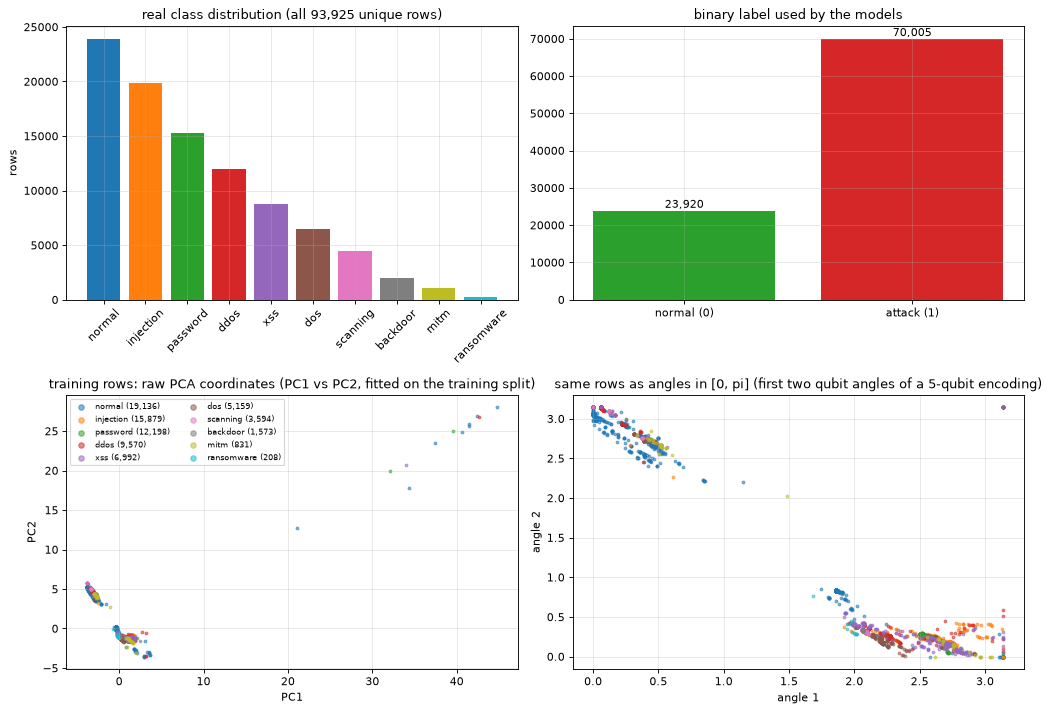

training split 75,140 rows, test split 18,785 rows; attack share of the test split 74.53 % (paper's all-attack accuracy: 74.56 %)


In [8]:
fam = DATA["fam"]; y_all = DATA["y"]
fam_order = list(pd.Series(fam).value_counts().index)
palette = plt.get_cmap("tab10")
fam_color = {f: palette(i % 10) for i, f in enumerate(fam_order)}

tr0, te0 = make_split(SEEDS[0])
Z5tr, _ = prep(tr0, te0, 5, math.pi)                                  # angles that a 5-qubit circuit receives (pre-bandwidth tuning: pi)
P2, _ = pca_coords(tr0, te0, 5)                                       # raw PCA coordinates (after signed log1p + standardisation), fitted on the training split
sel = np.random.default_rng(SEED).choice(len(tr0), size=min(4000, len(tr0)), replace=False)
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
counts = pd.Series(fam).value_counts()
ax[0, 0].bar(counts.index, counts.values, color=[fam_color[f] for f in counts.index]); ax[0, 0].set_title(f"real class distribution (all {len(fam):,} unique rows)")
ax[0, 0].tick_params(axis="x", rotation=45); ax[0, 0].set_ylabel("rows")
bc = np.bincount(y_all); ax[0, 1].bar(["normal (0)", "attack (1)"], bc, color=["tab:green", "tab:red"]); ax[0, 1].set_title("binary label used by the models")
for k, v in enumerate(bc): ax[0, 1].text(k, v, f"{v:,}", ha="center", va="bottom")
for f in fam_order:
    m = fam[tr0][sel] == f
    ax[1, 0].scatter(P2[sel][m, 0], P2[sel][m, 1], s=6, alpha=0.55, color=fam_color[f], label=f"{f} ({(fam[tr0] == f).sum():,})")
    ax[1, 1].scatter(Z5tr[sel][m, 0], Z5tr[sel][m, 1], s=6, alpha=0.55, color=fam_color[f])
ax[1, 0].set_title("training rows: raw PCA coordinates (PC1 vs PC2, fitted on the training split)"); ax[1, 0].set_xlabel("PC1"); ax[1, 0].set_ylabel("PC2")
ax[1, 1].set_title("same rows as angles in [0, pi] (first two qubit angles of a 5-qubit encoding)"); ax[1, 1].set_xlabel("angle 1"); ax[1, 1].set_ylabel("angle 2")
ax[1, 0].legend(fontsize=7, markerscale=2, ncol=2)
plt.tight_layout(); plt.show()
print(f"training split {len(tr0):,} rows, test split {len(te0):,} rows; attack share of the test split {100 * y_all[te0].mean():.2f} % (paper's all-attack accuracy: 74.56 %)")

**What the plots show.** ToN_IoT has ten real classes. After the paper's de-duplication the table is dominated by *normal* (about 25 %) and by the *injection*, *password*, *DDoS* and *XSS* attacks; *ransomware* shrinks to a few hundred rows and *MITM* stays at about 1,000. In two PCA dimensions several attack types overlap strongly (that is why the paper needs 5 to 7 qubits to reach 93 to 96 %), while the *normal* traffic and a few attack families form separate clouds. After the `[0, pi]` rescaling the cloud is the same, only squeezed into the box that the rotation gates use; points outside the training percentile range are clipped to the border.

## 2. Preprocessing, kernel bandwidth and classical baselines

### 2.1 Kernel bandwidth (angle range)

The paper only says "min-max scaling". For a quantum kernel the scale of the angles acts like the bandwidth of a classical RBF kernel, so it matters. As prescribed by the project conventions it is chosen on a **validation split of the training data only** (never on the test split), with the exact kernel. The headline 5-qubit `ZFeatureMap` circuit fixes one global value (used for the classical baselines, the configuration scan, the VQC and, in `FAST_MODE`, for every circuit). In the large run (`PER_CIRCUIT_AMAX = True`) every Pegasos-QSVC circuit of Tables III and X gets its own value, tuned in the same way for that circuit when it is first used (`# CHOICE`; the grid is `AMAX_GRID`; the mean over five model seeds is used because Pegasos is random and a single 100-step run scatters by 2 to 4 accuracy points).

In [9]:
def tune_amax(fm_name="Z", q=5, reps=1, n_val=3000, n_seeds=5):
    """Validation accuracy of the exact Pegasos-QSVC (mean over model seeds, Pegasos is random) for every candidate angle range; training data only."""
    y = DATA["y"]; tr, _ = make_split(SEEDS[0])
    itr, iva = train_test_split(tr, test_size=0.2, stratify=DATA["fam"][tr], random_state=SEEDS[0])
    iva = take(iva, y, n_val, SEEDS[0]); scores = {}
    for a in AMAX_GRID:
        Ztr, Zva = prep(itr, iva, q, a)
        kern = BatchedStatevectorKernel(feature_map(fm_name, q, reps)); accs = []
        pool = take(np.arange(len(itr)), y[itr], min(PEGASOS_POOL, 1500), SEEDS[0]); kern._states(Ztr[pool])          # Pegasos draws its rows from a stratified pool (see run_qsvc)
        for ms in PEGASOS_SEEDS[:n_seeds]:
            algorithm_globals.random_seed = ms
            m = BatchPegasos(quantum_kernel=kern, C=1000, num_steps=100, seed=ms).fit(Ztr[pool], y[itr][pool])
            accs.append(accuracy_score(y[iva], m.predict(Zva)))
        scores[round(a / math.pi, 2)] = float(np.mean(accs))
    best = max(scores, key=scores.get)
    return best * math.pi, scores
t0 = time.time()
AMAX, sc_ = tune_amax()
print(f"global bandwidth (headline circuit, 5-qubit ZFeatureMap): validation accuracy by angle range (multiples of pi) {({k: round(v, 4) for k, v in sc_.items()})} -> a_max = {AMAX / math.pi:.2f} pi  ({time.time() - t0:.0f} s)")
AMAX_KEY = {"Z5r1": AMAX}
def amax_for(key):
    """Per-circuit kernel bandwidth, tuned on the validation split of the training data (never on test rows)."""
    if not PER_CIRCUIT_AMAX:
        return AMAX
    if key not in AMAX_KEY:
        c = QSVC_CFG[key]; AMAX_KEY[key] = tune_amax(c["fm"], c["q"], c["r"])[0]
    return AMAX_KEY[key]

global bandwidth (headline circuit, 5-qubit ZFeatureMap): validation accuracy by angle range (multiples of pi) {0.5: 0.8438, 1.0: 0.8879, 2.0: 0.8579} -> a_max = 1.00 pi  (9 s)


### 2.2 Classical baselines on exactly the same inputs

SVM (RBF), XGBoost, random forest and a small neural network receive the same PCA features as the quantum models (same split, same scaling, same number of components as qubits), plus the same models on **all** numeric features. The conference paper reports no classical numbers of its own (it only cites that classical IDS "have already reached peak performance"), so these rows are an added reference, not a reproduction target. To keep the run time reasonable the classical models are trained on a stratified subset of the training split (`N_CLASSICAL_TRAIN` rows; the kernel SVM, which is quadratic in the number of rows, on `N_SVC_TRAIN` rows; `# CHOICE`) and evaluated on the whole test split.

model,SVM(rbf),XGBoost,RF,NN
q,,,,
3,91.94,98.30,98.51,92.14
5,93.26,98.79,99.07,96.27
7,93.31,99.09,99.12,95.89
all,97.41,99.33,99.38,97.43


model,SVM(rbf),XGBoost,RF,NN
F1 [%],,,,
3,94.78,98.86,99.00,94.86
5,95.61,99.19,99.38,97.52
7,95.64,99.39,99.41,97.23
all,98.26,99.55,99.59,98.28


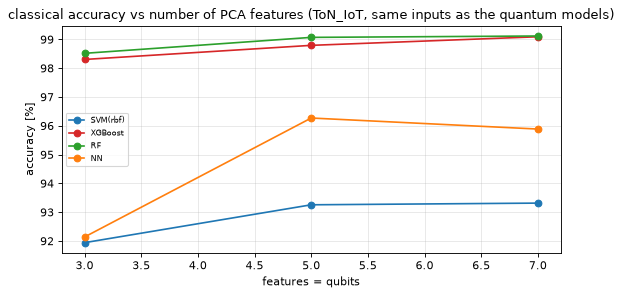

(97 s)  all-attack baseline accuracy on the test split: 74.53 %


In [10]:
CLASSIFIERS = {
    "SVM(rbf)": lambda s: SVC(kernel="rbf", C=1.0, random_state=s),
    "XGBoost": lambda s: XGBClassifier(n_estimators=100, random_state=s, n_jobs=2, eval_metric="logloss", verbosity=0),
    "RF": lambda s: RandomForestClassifier(100, random_state=s, n_jobs=2),
    "NN": lambda s: MLPClassifier((64, 32), max_iter=200, early_stopping=True, n_iter_no_change=8, random_state=s),
}
t0 = time.time()
y = DATA["y"]; tr, te = make_split(SEEDS[0])
sv_idx = take(np.arange(len(tr)), y[tr], N_SVC_TRAIN, SEEDS[0])
cl_idx = take(np.arange(len(tr)), y[tr], N_CLASSICAL_TRAIN, SEEDS[0])
def fit_eval(name, Ztr, Zte, q_label):
    sub = sv_idx if name == "SVM(rbf)" else cl_idx
    t1 = time.time(); m = CLASSIFIERS[name](SEEDS[0]).fit(Ztr[sub], y[tr][sub]); p = m.predict(Zte)
    log(kind="classical", model=name, q=q_label, seed=SEEDS[0], n_train=len(sub), n_test=len(te), t_fit=time.time() - t1, **metrics(y[te], p))
for q in CLASSICAL_Q:
    Ztr, Zte = prep(tr, te, q, AMAX)
    for name in CLASSIFIERS:
        fit_eval(name, Ztr, Zte, q)
Ftr, Fte = prep_full(tr, te)
for name in CLASSIFIERS:
    fit_eval(name, Ftr, Fte, "all")
cl = pd.DataFrame([r for r in RES if r["kind"] == "classical"])
display(cl.pivot_table(index="q", columns="model", values="acc", sort=False).round(2))
display(cl.pivot_table(index="q", columns="model", values="f1", sort=False).round(2).rename_axis("F1 [%]"))
fig, ax = plt.subplots(1, 1, figsize=(7, 3.8))
for name, c in zip(CLASSIFIERS, ["tab:blue", "tab:red", "tab:green", "tab:orange"]):
    s = cl[(cl.model == name) & (cl.q != "all")].sort_values("q")
    ax.plot(s.q.astype(int), s.acc, "-o", color=c, label=name)
ax.set_title("classical accuracy vs number of PCA features (ToN_IoT, same inputs as the quantum models)"); ax.set_xlabel("features = qubits"); ax.set_ylabel("accuracy [%]"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"({time.time() - t0:.0f} s)  all-attack baseline accuracy on the test split: {100 * y[te].mean():.2f} %")

## Quantum Circuit Architecture

This section draws the circuits that the notebook really runs, taken from the very objects used later: the feature-map circuits inside the kernel objects of the Pegasos-QSVC (ideal and noisy), the circuit inside Qiskit's `VQC`, and the circuit of the quantum layer of the hybrid network. For each one the number of qubits, the depth (after writing Qiskit's composite blocks out as elementary gates), the number of free parameters and the CNOT count after transpilation for `FakePerth` (the 7-qubit device coupling map shared by the three fake backends) are printed.

### Assumptions where the paper omits circuit details
* **Pauli feature maps**: the entanglement pattern is not stated, the Qiskit default (`full`) is used. `X`, `Y`, `Z` (single-qubit strings) therefore give no entanglement; two-qubit strings (`XX`, `ZZ`, `YY`, ...) give one two-qubit rotation per qubit pair.
* **ZZFeatureMap** uses the entanglement named in the configuration (`linear`, `full`, `circular`).
* **Ansatz** (paper Figs. 1 to 4): `RealAmplitudes` (RY + CX), `EfficientSU2` (RY, RZ + CX), `TwoLocal` (RY + CX, full entanglement), `PauliTwoDesign` (initial RY(pi/4), then random X/Y/Z rotations and CZ layers, drawn from a fixed seed); Qiskit defaults for the rest and `reps` as in the tables.
* **VQC measurement**: Qiskit's `VQC` measures all qubits and maps the bitstring to a class by parity; one-hot labels. The feature map is repeated once (`reps=1`), as in the paper.
* **Hybrid quantum layer**: feature map + ansatz, observable `Z...Z` on all qubits (Fig. 7 of the paper does not give the observable); the inputs are the `n_qubits` outputs of the last linear layer.
* **Noisy runs**: transpilation with optimisation level 1 for the fake device (Qiskit's default layout choice), basis gates `cx, rz, sx, x`; the noise model comes from the device snapshot (gate errors, thermal relaxation, readout errors).

### Drawings

QSVC ideal kernel: 5-qubit ZFeatureMap, r=1 (this circuit is what the statevector simulator runs for each row)
  qubits: 5 | depth (elementary gates): 2 | free parameters: 5 | after transpiling for FakePerth: depth 4, CX 0


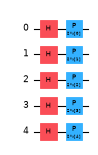

QSVC noisy kernel circuit U(x) then U(y)^dagger with measurement (10 free parameters: 5 for x, 5 for y)
  qubits: 5 | depth (elementary gates): 5 | free parameters: 10 | after transpiling for FakePerth: depth 9, CX 0


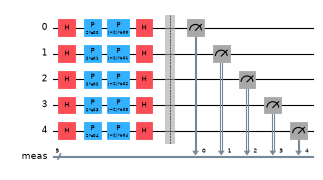

transpiled for FakePerth (what the noisy simulator executes): depth 9 | CX 0 | ops {'rz': 30, 'sx': 10, 'measure': 5, 'barrier': 1}


In [11]:
DRAW_BASIS = ["h", "p", "rz", "ry", "rx", "sx", "sxdg", "s", "sdg", "cx", "cz", "x"]
def show_circuit(qc, title, fold=36, scale=0.5, backend="FakePerth", trainable=None):
    dec = transpile(qc, basis_gates=DRAW_BASIS, optimization_level=0)       # Qiskit's composite blocks written out as elementary gates (readable drawing)
    tq = transpile(dec, FAKE[backend], optimization_level=1, seed_transpiler=SEED)
    print(f"{title}\n  qubits: {qc.num_qubits} | depth (elementary gates): {dec.depth()} | free parameters: {qc.num_parameters}"
          + (f" (trainable: {trainable})" if trainable is not None else "")
          + f" | after transpiling for {backend}: depth {tq.depth()}, CX {tq.count_ops().get('cx', 0)}")
    display(dec.draw("mpl", fold=fold, scale=scale))
    plt.close("all")
    return dict(circuit=title, qubits=qc.num_qubits, depth=dec.depth(), params=qc.num_parameters, cx_transpiled=tq.count_ops().get("cx", 0), depth_transpiled=tq.depth())

ARCH = []
# 1. Pegasos-QSVC: the kernel circuits for the paper's headline configuration (5-qubit ZFeatureMap, r=1), ideal and noisy
fm_demo = feature_map("Z", 5, 1)
kid = BatchedStatevectorKernel(fm_demo)
assert kid.executed.data[-1].operation.name == "save_statevector" and len(kid.executed.data) == len(fm_demo.data) + 1   # executed = feature map + save
ARCH.append(show_circuit(fm_demo, "QSVC ideal kernel: 5-qubit ZFeatureMap, r=1 (this circuit is what the statevector simulator runs for each row)"))
knz = NoisyFidelityKernel(feature_map("Z", 5, 1), "FakePerth")
ARCH.append(show_circuit(knz.logical, "QSVC noisy kernel circuit U(x) then U(y)^dagger with measurement (10 free parameters: 5 for x, 5 for y)"))
print("transpiled for FakePerth (what the noisy simulator executes): depth", knz.executed.depth(), "| CX", knz.cx, "| ops", dict(knz.executed.count_ops()))

QSVC feature map: q=6 ZZ(Linear) r=1
  qubits: 6 | depth (elementary gates): 17 | free parameters: 6 | after transpiling for FakePerth: depth 20, CX 11


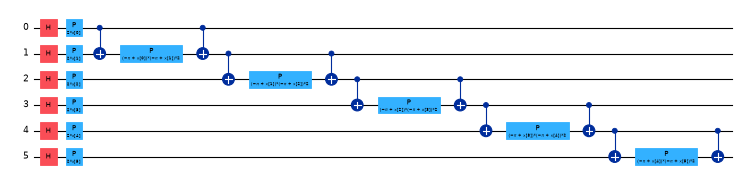

QSVC feature map: q=6 Pauli[ZX] r=1
  qubits: 6 | depth (elementary gates): 38 | free parameters: 6 | after transpiling for FakePerth: depth 64, CX 52


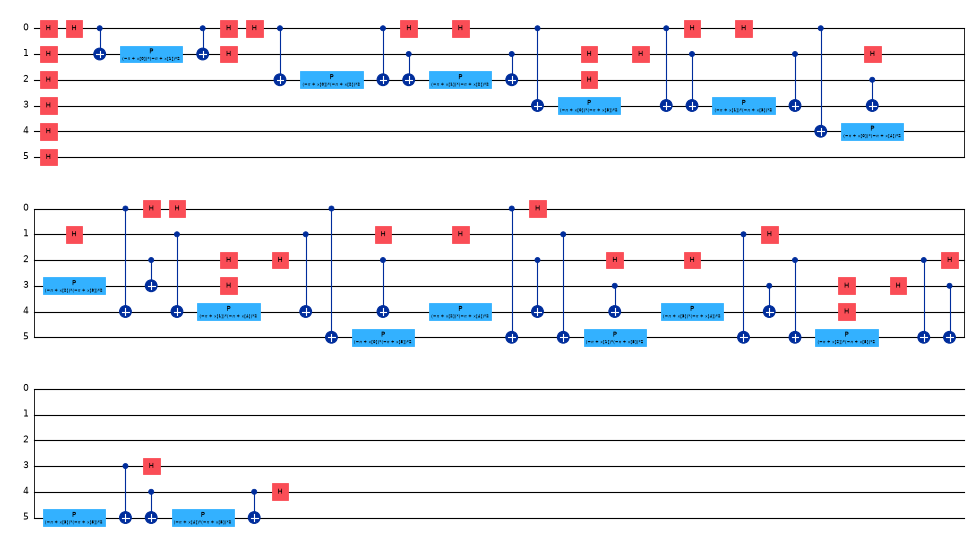

QSVC feature map: q=4 Pauli[Z,YY] r=1
  qubits: 4 | depth (elementary gates): 27 | free parameters: 4 | after transpiling for FakePerth: depth 32, CX 18


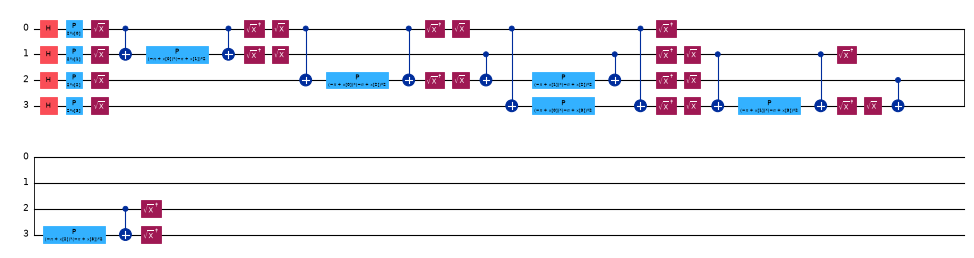

QSVC feature map: q=7 ZFeatureMap r=2
  qubits: 7 | depth (elementary gates): 4 | free parameters: 7 | after transpiling for FakePerth: depth 8, CX 0


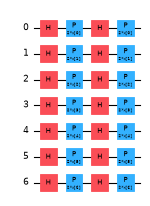

QSVC feature map: q=5 Pauli[XX] r=2
  qubits: 5 | depth (elementary gates): 62 | free parameters: 5 | after transpiling for FakePerth: depth 90, CX 70


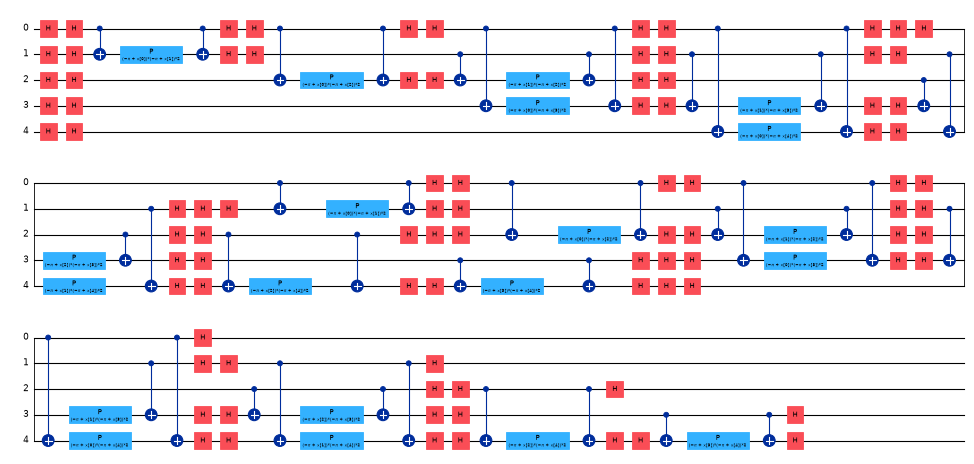

QSVC feature map: q=6 Pauli[Z,XX] r=2
  qubits: 6 | depth (elementary gates): 79 | free parameters: 6 | after transpiling for FakePerth: depth 126, CX 117


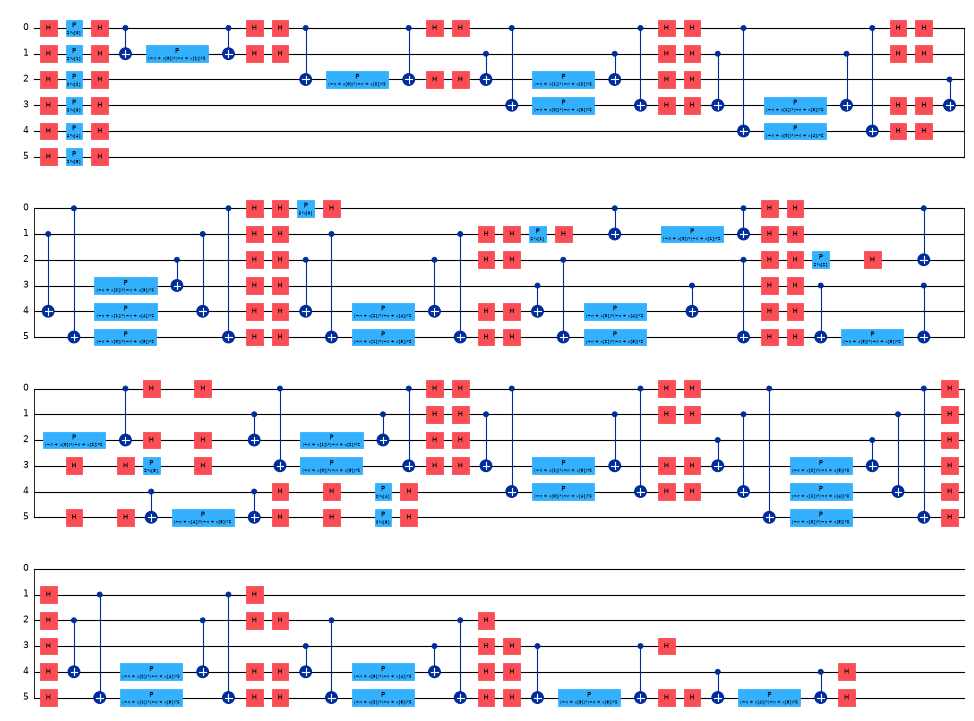

QSVC feature map: q=4 Pauli[Z,Y,ZZ] r=2
  qubits: 4 | depth (elementary gates): 37 | free parameters: 4 | after transpiling for FakePerth: depth 81, CX 33


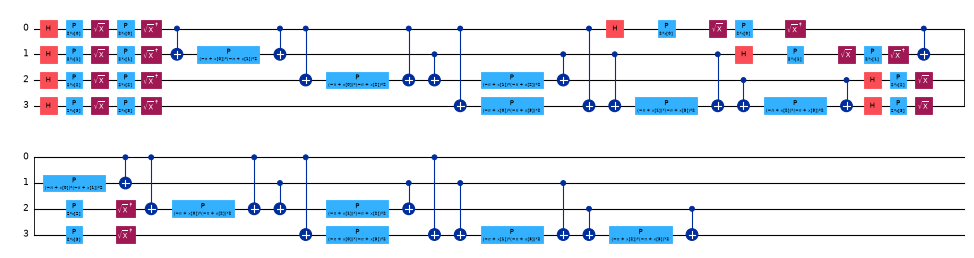

QSVC feature map: q=5 ZZ(Linear) r=3
  qubits: 5 | depth (elementary gates): 30 | free parameters: 5 | after transpiling for FakePerth: depth 36, CX 24


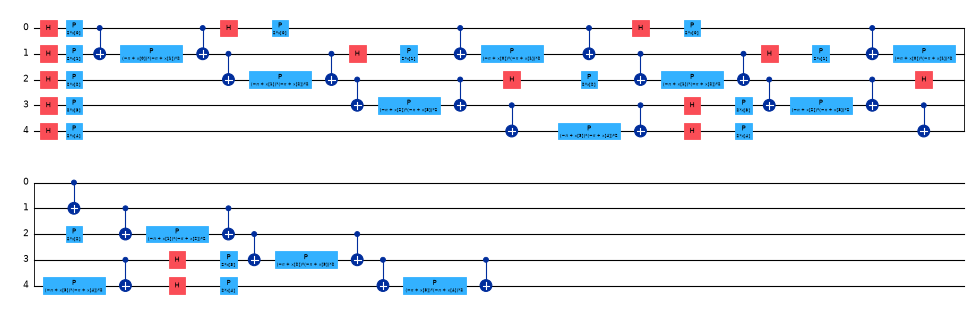

In [12]:
# 2. The other feature maps of the Pegasos-QSVC configurations (each distinct architecture once)
seen = set()
for key in list(dict.fromkeys(QSVC_NOISELESS + QSVC_NOISY)):
    c = QSVC_CFG[key]; sig = (c["fm"], c["q"], c["r"])
    if sig in seen or key == "Z5r1":
        continue
    seen.add(sig)
    ARCH.append(show_circuit(feature_map(c["fm"], c["q"], c["r"]), f"QSVC feature map: {c['label']}"))

VQC object circuit ops: {'ry': 9, 'cx': 4, 'h': 3, 'sx': 3, 'p': 3, 'sxdg': 3}


VQC 3q Pauli[Y] + RealAmplitudes r=2
  qubits: 3 | depth (elementary gates): 11 | free parameters: 12 (trainable: 9) | after transpiling for FakePerth: depth 19, CX 4


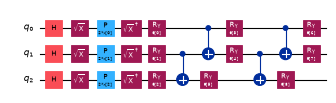

VQC object circuit ops: {'ry': 9, 'cx': 4, 'h': 3, 'sx': 3, 'p': 3, 'sxdg': 3}
VQC 3q Pauli[Y] + RealAmplitudes r=2 (ansatz scan)
  qubits: 3 | depth (elementary gates): 11 | free parameters: 12 (trainable: 9) | after transpiling for FakePerth: depth 19, CX 4


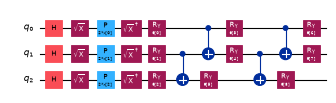

VQC object circuit ops: {'ry': 9, 'rz': 9, 'cx': 4, 'h': 3, 'sx': 3, 'p': 3, 'sxdg': 3}


VQC 3q Pauli[Y] + EfficientSU2 r=2 (ansatz scan)
  qubits: 3 | depth (elementary gates): 14 | free parameters: 21 (trainable: 18) | after transpiling for FakePerth: depth 22, CX 4


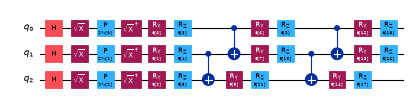

VQC object circuit ops: {'ry': 9, 'cx': 6, 'h': 3, 'sx': 3, 'p': 3, 'sxdg': 3}


VQC 3q Pauli[Y] + TwoLocal r=2 (ansatz scan)
  qubits: 3 | depth (elementary gates): 13 | free parameters: 12 (trainable: 9) | after transpiling for FakePerth: depth 31, CX 12


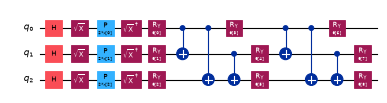

VQC object circuit ops: {'ry': 6, 'cz': 4, 'h': 3, 'sx': 3, 'p': 3, 'sxdg': 3, 'rx': 3, 'rz': 3}
VQC 3q Pauli[Y] + PauliTwoDesign r=2 (ansatz scan)
  qubits: 3 | depth (elementary gates): 12 | free parameters: 12 (trainable: 9) | after transpiling for FakePerth: depth 29, CX 4


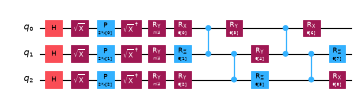

In [13]:
# 3. VQC circuits (the circuit stored inside Qiskit's VQC object: feature map + ansatz + measurement). One drawing per distinct architecture.
vqc_archs = {k: VQC_CFG[k] for k in dict.fromkeys(VQC_OPT_CFGS + [r[0] for r in VQC_NOISY_RUNS])}
for a_ in ["RealAmplitudes", "EfficientSU2", "TwoLocal", "PauliTwoDesign"]:        # the four ansatz of the paper (Figs. 1-4) on 3 qubits, as used in the ansatz scan
    vqc_archs[f"scan-{a_}"] = dict(label=f"3q Pauli[Y] + {a_} r=2 (ansatz scan)", fm="Y", q=3, ans=a_, reps=2)
for key, c in vqc_archs.items():
    v = VQC(feature_map=feature_map(c["fm"], c["q"], 1), ansatz=build_ansatz(c["ans"], c["q"], c["reps"]))
    print("VQC object circuit ops:", dict(v.circuit.count_ops()))
    ARCH.append(show_circuit(v.circuit, f"VQC {c['label']}", trainable=v.ansatz.num_parameters))

HQNN quantum layer 5q Pauli[ZY] + EfficientSU2 r=1 (observable Z^5)
  qubits: 5 | depth (elementary gates): 38 | free parameters: 25 (trainable: 20) | after transpiling for FakePerth: depth 71, CX 42


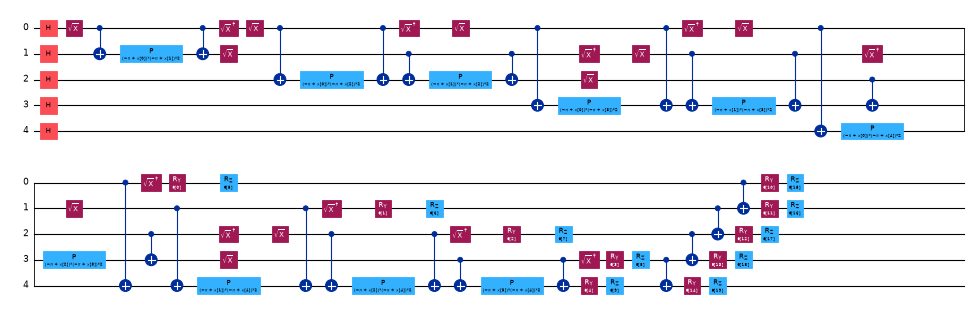

Classical part of every hybrid network (paper Fig. 7): n_features -> Linear(64) -> ReLU -> Linear(64) -> ReLU -> Linear(n_qubits) -> quantum layer (inputs = n_qubits rotation angles, weights = ansatz angles) -> <Z...Z> in [-1, 1]; class = sign


,circuit,qubits,depth,params,cx_transpiled,depth_transpiled
0,"QSVC ideal kernel: 5-qubit ZFeatureMap, r=1 (t...",5,2,5,0,4
1,QSVC noisy kernel circuit U(x) then U(y)^dagge...,5,5,10,0,9
2,QSVC feature map: q=6 ZZ(Linear) r=1,6,17,6,11,20
3,QSVC feature map: q=6 Pauli[ZX] r=1,6,38,6,52,64
4,"QSVC feature map: q=4 Pauli[Z,YY] r=1",4,27,4,18,32
5,QSVC feature map: q=7 ZFeatureMap r=2,7,4,7,0,8
6,QSVC feature map: q=5 Pauli[XX] r=2,5,62,5,70,90
7,"QSVC feature map: q=6 Pauli[Z,XX] r=2",6,79,6,117,126
8,"QSVC feature map: q=4 Pauli[Z,Y,ZZ] r=2",4,37,4,33,81
9,QSVC feature map: q=5 ZZ(Linear) r=3,5,30,5,24,36


In [14]:
# 4. Hybrid network quantum layer: feature map + ansatz, observable Z...Z (the classical Linear-ReLU layers are described as text below)
for key in HQNN_CFGS:
    c = HQNN_CFG[key]
    fm_h = feature_map(c["fm"], c["q"], c["fr"]); an_h = build_ansatz(c["ans"], c["q"], c["ar"])
    ARCH.append(show_circuit(fm_h.compose(an_h), f"HQNN quantum layer {c['label']} (observable Z^{c['q']})", trainable=an_h.num_parameters))
print(f"Classical part of every hybrid network (paper Fig. 7): n_features -> Linear({HQNN_HIDDEN}) -> ReLU -> Linear({HQNN_HIDDEN}) -> ReLU -> Linear(n_qubits) -> quantum layer "
      "(inputs = n_qubits rotation angles, weights = ansatz angles) -> <Z...Z> in [-1, 1]; class = sign")
display(pd.DataFrame(ARCH))

## 3. Pegasos-QSVC (paper Section IV-A)

A quantum kernel `k(x, y) = |<phi(x)|phi(y)>|^2` measures how similar two connections look after the feature map `phi` has loaded them into a quantum state. **Pegasos** is a stochastic sub-gradient solver for the SVM objective: in each of `steps` iterations it draws one random training row, checks whether the margin condition `y * (C / t) * sum_j alpha_j y_j k(x, x_j) < 1` is violated and, if so, adds that row to the support set. After 100 steps there are only about 15 to 30 support vectors, which is why training is cheap (independent of the training-set size, as the paper says) and prediction (one kernel value per support vector and test row) dominates the cost.

### 3.1 Correctness checks of the helper classes
Before trusting any number, the kernel implementations and the batched Pegasos decision function are checked against references.

In [15]:
fm_chk = feature_map("ZZ-linear", 4, 1)
xs, ys_ = rng.uniform(0, math.pi, (6, 4)), rng.uniform(0, math.pi, (5, 4))
K_batched = BatchedStatevectorKernel(fm_chk).evaluate(xs, ys_)
K_qiskit = FidelityStatevectorKernel(feature_map=fm_chk).evaluate(xs, ys_)
K_hand = np.array([[abs(Statevector(fm_chk.assign_parameters(a)).inner(Statevector(fm_chk.assign_parameters(b)))) ** 2 for b in ys_] for a in xs])
assert np.allclose(K_batched, K_qiskit) and np.allclose(K_batched, K_hand)
print("exact kernel: batched Aer == FidelityStatevectorKernel == hand-computed |<phi(a)|phi(b)>|^2  ->  OK")

# batched Pegasos decision function equals the parent's per-sample implementation
y = DATA["y"]; tr, te = make_split(SEEDS[0]); tr_s, te_s = take(tr, y, 300, SEEDS[0]), take(te, y, 25, SEEDS[0])
Ztr_, Zte_ = prep(tr_s, te_s, 4, AMAX)
algorithm_globals.random_seed = SEEDS[0]
m_chk = BatchPegasos(quantum_kernel=BatchedStatevectorKernel(feature_map("Z", 4, 1)), C=1000, num_steps=40, seed=SEEDS[0]).fit(Ztr_, y[tr_s])
assert np.allclose(m_chk.decision_function(Zte_), PegasosQSVC.decision_function(m_chk, Zte_))
print("BatchPegasos.decision_function == PegasosQSVC.decision_function on 25 test rows  ->  OK")

# the noisy kernel with the noise switched off must reproduce the exact kernel up to shot noise
fm_n = feature_map("Z,YY", 3, 1); kn = NoisyFidelityKernel(fm_n, "FakePerth")
ideal_sim = AerSimulator(method="statevector"); a_, b_ = xs[:3, :3], ys_[:3, :3]
vals = np.concatenate([np.repeat(a_, 3, axis=0), np.tile(b_, (3, 1))], axis=1)
names = [f"a{i:02d}" for i in range(3)] + [f"b{i:02d}" for i in range(3)]
binds = {p: vals[:, names.index(p.name)].tolist() for p in kn.executed.parameters}
cnt = ideal_sim.run(kn.executed, parameter_binds=[binds], shots=20000, seed_simulator=1).result()
K_noiseless_circuit = np.array([cnt.get_counts(i).get("000", 0) / 20000 for i in range(9)]).reshape(3, 3)
K_ref = BatchedStatevectorKernel(fm_n).evaluate(a_, b_)
print("transpiled compute-uncompute circuit without noise vs exact kernel, max abs difference:", float(np.abs(K_noiseless_circuit - K_ref).max()))
assert np.abs(K_noiseless_circuit - K_ref).max() < 0.03

exact kernel: batched Aer == FidelityStatevectorKernel == hand-computed |<phi(a)|phi(b)>|^2  ->  OK

BatchPegasos.decision_function == PegasosQSVC.decision_function on 25 test rows  ->  OK


transpiled compute-uncompute circuit without noise vs exact kernel, max abs difference: 0.005667061229816472


### 3.2 Training and evaluating one configuration
`run_qsvc` is the single entry point: it draws the split for a given seed, fits the preprocessing on the training rows, trains `BatchPegasos` with the ideal or a noisy kernel, and logs accuracy / precision / recall / F1 / balanced accuracy (attack = positive class), the number of support vectors, the CNOT count of the transpiled kernel circuit and the timings. `n_test` limits the evaluation to a stratified subset of the test split (the noisy runs need one circuit execution per kernel entry).

In [16]:
QCACHE = {}; KCACHE = {}; CXCACHE = {}
def run_qsvc(key, seed, C=1000, steps=100, backend=None, n_test=None, cfg=None):
    if n_test is None and backend is None:
        n_test = IDEAL_N_TEST
    ck = (key, seed, C, steps, backend, n_test)
    if cfg is None and ck in QCACHE:
        return QCACHE[ck]
    c = cfg or QSVC_CFG[key]; y = DATA["y"]
    tr, te = make_split(SEEDS[0]); te = take(te, y, n_test, SEEDS[0])         # one fixed data split; `seed` is the model seed (Pegasos draws its rows at random)
    Ztr, Zte = prep(tr, te, c["q"], AMAX if cfg is not None else amax_for(key))
    fm = feature_map(c["fm"], c["q"], c["r"])
    if backend is None:
        if cfg is None:                                                   # statevectors of the test rows are reused across seeds, C and steps (small FIFO cache)
            if key not in KCACHE:
                if len(KCACHE) >= 3:
                    KCACHE.pop(next(iter(KCACHE)))
                KCACHE[key] = BatchedStatevectorKernel(fm)
            kern = KCACHE[key]
        else:
            kern = BatchedStatevectorKernel(fm)
    else:
        kern = NoisyFidelityKernel(fm, backend, SHOTS, seed)
    if backend is not None:
        cx = kern.cx
    else:                                                          # CNOTs of the compute-uncompute circuit on the 7-qubit device (not defined above 7 qubits)
        sig = (c["fm"], c["q"], c["r"])
        if sig not in CXCACHE:
            CXCACHE[sig] = NoisyFidelityKernel(fm, "FakePerth").cx if c["q"] <= 7 else np.nan
        cx = CXCACHE[sig]
    algorithm_globals.random_seed = seed
    pool = take(np.arange(len(tr)), y[tr], SCAN_POOL if cfg is not None else PEGASOS_POOL, SEEDS[0])       # CHOICE: Pegasos draws its ~100 rows from a stratified pool (a random draw from the pool is statistically a random draw from the whole split)
    fit_kern = kern
    if backend is not None and not NOISY_TRAINING:                        # FAST_MODE: the model is trained with the exact kernel and only the prediction runs on the noisy device kernel
        fit_kern = BatchedStatevectorKernel(fm)
    if isinstance(fit_kern, BatchedStatevectorKernel):
        fit_kern._states(Ztr[pool])                                       # states of the pool are computed once (batched) instead of one simulator call per Pegasos step
    t0 = time.time(); m = BatchPegasos(quantum_kernel=fit_kern, C=C, num_steps=steps, seed=seed).fit(Ztr[pool], y[tr][pool]); t_fit = time.time() - t0
    m._quantum_kernel = kern                                              # prediction uses the kernel of the run (the noisy device kernel for the noisy runs)
    t0 = time.time(); p = m.predict(Zte); t_pred = time.time() - t0
    row = log(kind="qsvc", model="Pegasos-QSVC", key=key, backend=backend or "ideal", seed=seed, C=C, steps=steps, n_train=len(tr), n_pool=len(pool), n_test=len(te),
              n_sv=len(m._alphas), cx=cx, t_fit=t_fit, t_pred=t_pred, **metrics(y[te], p))
    if cfg is None:
        QCACHE[ck] = row
    return row
r = run_qsvc(TABLE2_CIRCUIT, PEGASOS_SEEDS[0])
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in r.items()})

def qmean(key, seeds=None, **kw):
    """Mean (and std of the accuracy) of run_qsvc over several Pegasos model seeds on the same data split."""
    rr = [run_qsvc(key, s, **kw) for s in (seeds or PEGASOS_SEEDS[:3])]
    out = {k: float(np.mean([r[k] for r in rr])) for k in ["acc", "prec", "rec", "f1", "bacc", "n_sv", "t_fit", "t_pred"]}
    out.update(acc_std=float(np.std([r["acc"] for r in rr])), f1_std=float(np.std([r["f1"] for r in rr])), cx=rr[0]["cx"], n_test=rr[0]["n_test"], n_seeds=len(rr))
    return out

{'kind': 'qsvc', 'model': 'Pegasos-QSVC', 'key': 'Z5r1', 'backend': 'ideal', 'seed': 1, 'C': 1000, 'steps': 100, 'n_train': 75140, 'n_pool': 3000, 'n_test': 4000, 'n_sv': 17, 'cx': 0, 't_fit': 0.05, 't_pred': 1.87, 'acc': 88.22, 'prec': 87.11, 'rec': 98.83, 'f1': 92.6, 'bacc': 78.02}


### 3.3 Regularisation `C` and number of steps (paper Table II)
The paper does not say which circuit Table II belongs to; its headline 5-qubit `ZFeatureMap` (r=1) is used (`# CHOICE`). Each row is the mean over three Pegasos model seeds. The signature behaviour to check: a large `C` works, a small `C` collapses to "predict attack for everything" (accuracy = share of attacks in the test set, recall 100 %). The number of steps trades accuracy against time: the paper tried 20, 50, 100, 200, 500 and found 100 the best compromise.

In [17]:
rows = []
for C in C_SWEEP:
    r = qmean(TABLE2_CIRCUIT, C=C)
    p = TABLE2[C]
    rows.append({"C": C, "acc": r["acc"], "acc std": r["acc_std"], "prec": r["prec"], "rec": r["rec"], "F1": r["f1"], "support vectors": r["n_sv"],
                 "paper acc": p[0], "paper prec": p[1], "paper rec": p[2], "paper F1": p[3]})
display(pd.DataFrame(rows).round(2))
rows = []
for st in STEPS_SWEEP:
    r = qmean(TABLE2_CIRCUIT, steps=st)
    rows.append({"steps": st, "acc": r["acc"], "acc std": r["acc_std"], "F1": r["f1"], "train time [s]": r["t_fit"], "predict time [s]": r["t_pred"], "support vectors": r["n_sv"]})
STEPS_TAB = pd.DataFrame(rows); display(STEPS_TAB.round(2))
print("paper: 100 steps is the best trade-off between accuracy and time; 20/50/100/200/500 were tried")

,C,acc,acc std,prec,rec,F1,support vectors,paper acc,paper prec,paper rec,paper F1
0,1000,88.43,0.48,90.81,94.22,92.39,19.00,92.25,92.77,97.18,94.92
1,100,89.68,1.41,91.82,94.63,93.17,25.33,91.61,92.02,97.18,94.53
2,10,80.64,4.33,79.96,99.22,88.49,51.67,79.16,89.48,81.65,85.39
3,1,74.52,0.00,74.52,100.00,85.40,97.33,74.56,74.56,100.00,85.42


,steps,acc,acc std,F1,train time [s],predict time [s],support vectors
0,20,83.32,6.46,89.64,0.01,0.02,7.0
1,100,88.43,0.48,92.39,0.07,0.64,19.0


paper: 100 steps is the best trade-off between accuracy and time; 20/50/100/200/500 were tried


### 3.4 Configuration scan: qubits, feature maps and repetitions (paper Section IV-A-3, 378 configurations)
The paper scans 2 to 10 qubits, 14 feature maps and 1 to 3 repetitions (378 Pegasos-QSVC runs, first without noise). The same scan is run here with the exact kernel on a stratified test subset of `SCAN_TEST` rows; `FAST_MODE` runs a thin slice of the grid (see the configuration cell), the full run covers all 378 cells. The paper's qualitative findings to check: (i) 2 to 3 qubits are poor, accuracy rises with qubits and saturates around 6 to 7; (ii) more repetitions stabilise the results but do not raise the peak much; (iii) `ZZFeatureMap` with `full`/`circular` entanglement beats `linear` at 1 to 2 repetitions, `linear` catches up at 3; (iv) `Z,YY` is consistently among the best maps; (v) the entanglement-free maps `X`, `Y`, `Z` are less stable.

30 configurations scanned in 100 s (paper: 378)
best configurations of the scan:


,fm,q,r,acc,f1,cx,n_sv
16,ZZ-full,7,1,90.55,93.46,142,16
8,ZZ-linear,5,1,89.70,93.07,14,18
14,ZZ-full,5,1,89.35,92.80,62,16
20,"Z,YY",5,1,89.25,92.75,62,14
3,Z,5,2,88.70,92.79,0,14
9,ZZ-linear,5,2,87.70,91.94,30,16
21,"Z,YY",5,2,87.55,91.45,136,16
1,Z,3,2,87.00,91.42,0,23


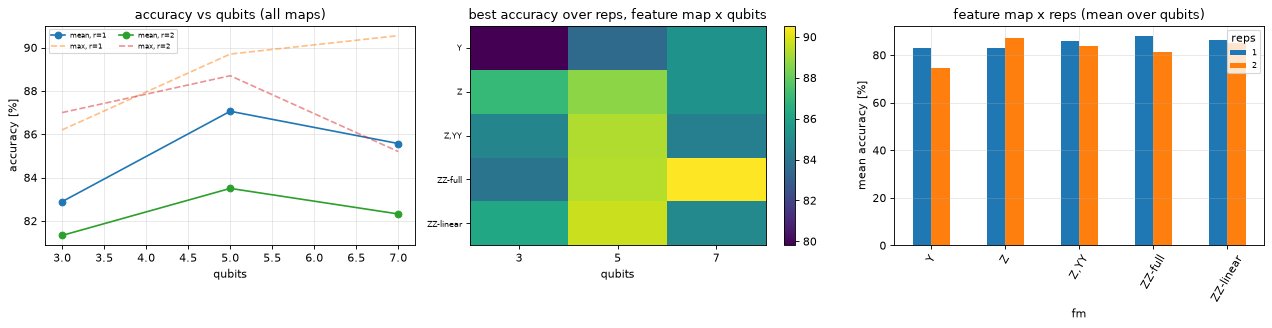

In [18]:
t0 = time.time(); SC = []
y = DATA["y"]
for fmn in SCAN_MAPS:
    for q in SCAN_QUBITS:
        for rp in SCAN_REPS:
            r = run_qsvc(f"scan-{fmn}-{q}-{rp}", SEEDS[0], n_test=SCAN_TEST, cfg=dict(fm=fmn, q=q, r=rp, label=f"{fmn} q={q} r={rp}"))
            SC.append(dict(fm=fmn, q=q, r=rp, acc=r["acc"], f1=r["f1"], cx=r["cx"], n_sv=r["n_sv"]))
        RES[:] = [x for x in RES if not (x["kind"] == "qsvc" and str(x["key"]).startswith("scan-"))]     # keep the global result log small
SC = pd.DataFrame(SC)
print(f"{len(SC)} configurations scanned in {time.time() - t0:.0f} s (paper: 378)")
print("best configurations of the scan:"); display(SC.sort_values("acc", ascending=False).head(8).round(2))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for rp in SCAN_REPS:
    g = SC[SC.r == rp].groupby("q").acc.agg(["mean", "max"])
    ax[0].plot(g.index, g["mean"], "-o", label=f"mean, r={rp}"); ax[0].plot(g.index, g["max"], "--", alpha=0.5, label=f"max, r={rp}")
ax[0].set_xlabel("qubits"); ax[0].set_ylabel("accuracy [%]"); ax[0].set_title("accuracy vs qubits (all maps)"); ax[0].legend(fontsize=6, ncol=2)
pv = SC.pivot_table(index="fm", columns="q", values="acc", aggfunc="max")
im = ax[1].imshow(pv.values, aspect="auto", cmap="viridis"); ax[1].set_xticks(range(pv.shape[1])); ax[1].set_xticklabels(pv.columns); ax[1].set_yticks(range(pv.shape[0])); ax[1].set_yticklabels(pv.index, fontsize=7)
ax[1].set_title("best accuracy over reps, feature map x qubits"); ax[1].set_xlabel("qubits"); ax[1].grid(False); plt.colorbar(im, ax=ax[1])
g = SC.groupby(["fm", "r"]).acc.mean().unstack(); g.plot.bar(ax=ax[2], rot=60); ax[2].set_ylabel("mean accuracy [%]"); ax[2].set_title("feature map x reps (mean over qubits)"); ax[2].legend(title="reps", fontsize=7)
plt.tight_layout(); plt.show()

### 3.5 Ideal simulation of the paper's best configurations (Table III)
For every selected configuration and every seed the whole test split is used (statevector kernel, no noise, `C=1000`, 100 steps). Pegasos draws its training rows at random, so every configuration is repeated with the model seeds in `PEGASOS_SEEDS` (same data split); the table shows mean +- std next to the paper's value (a single run per configuration, as in the paper, would scatter by about the printed std).

,configuration,acc,acc std,F1,F1 std,balanced acc,paper acc,paper F1,paper bal. acc,d acc,fit [s],predict [s],CX (device circuit)
0,q=6 ZZ(Linear) r=1,87.78,0.98,91.98,0.88,81.38,94.12,96.05,92.29,-6.34,0.06,0.56,24
1,q=6 Pauli[ZX] r=1,86.44,3.93,90.93,3.16,80.29,94.16,96.09,92.26,-7.72,0.06,0.98,98
2,"q=4 Pauli[Z,YY] r=1",85.51,3.22,90.53,2.83,76.68,93.17,95.50,89.34,-7.66,0.05,0.55,32
3,q=7 ZFeatureMap r=2,90.66,1.75,93.77,1.26,86.88,95.44,96.94,93.98,-4.78,0.06,0.59,0
4,q=5 Pauli[XX] r=2,87.82,1.58,92.09,1.15,80.50,94.14,96.06,92.43,-6.33,0.05,1.17,136
5,"q=6 Pauli[Z,XX] r=2",87.78,2.03,92.24,1.10,78.67,95.61,97.05,94.27,-7.83,0.06,2.01,230
6,"q=4 Pauli[Z,Y,ZZ] r=2",86.82,1.58,91.60,0.80,77.69,94.57,96.37,92.35,-7.74,0.05,0.70,64
7,q=5 ZZ(Linear) r=3,84.01,4.94,89.60,3.08,75.65,94.35,96.24,91.96,-10.34,0.05,0.71,46


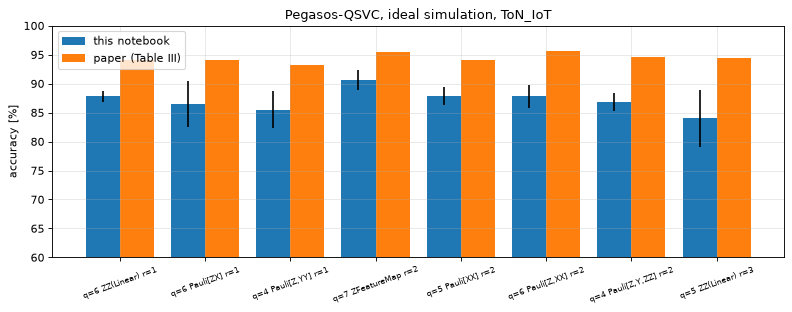

(88 s)


In [19]:
t0 = time.time(); rows = []
for key in QSVC_NOISELESS:
    rr = [run_qsvc(key, s) for s in PEGASOS_SEEDS]
    a, f = np.array([r["acc"] for r in rr]), np.array([r["f1"] for r in rr])
    pa, pp, pr, pf, pb = QSVC_CFG[key]["ideal"]
    rows.append({"configuration": QSVC_CFG[key]["label"], "acc": a.mean(), "acc std": a.std(), "F1": f.mean(), "F1 std": f.std(), "balanced acc": np.mean([r["bacc"] for r in rr]),
                 "paper acc": pa, "paper F1": pf, "paper bal. acc": pb, "d acc": a.mean() - pa, "fit [s]": np.mean([r["t_fit"] for r in rr]),
                 "predict [s]": np.mean([r["t_pred"] for r in rr]), "CX (device circuit)": rr[0]["cx"]})
T3 = pd.DataFrame(rows); display(T3.round(2))
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
x = np.arange(len(T3))
ax.bar(x - 0.2, T3["acc"], 0.4, yerr=T3["acc std"], label="this notebook"); ax.bar(x + 0.2, T3["paper acc"], 0.4, label="paper (Table III)")
ax.set_xticks(x); ax.set_xticklabels(T3["configuration"], rotation=20, fontsize=7); ax.set_ylim(60, 100); ax.set_ylabel("accuracy [%]"); ax.set_title("Pegasos-QSVC, ideal simulation, ToN_IoT"); ax.legend()
plt.tight_layout(); plt.show()
print(f"({time.time() - t0:.0f} s)")

### 3.6 Noisy simulation on the fake IBM devices (paper Table X)
The kernel entries are now estimated with 1024 shots on a density-matrix simulator that contains the full noise model of the device snapshot (gate errors, thermal relaxation, readout error), after transpiling the compute-uncompute circuit to the device's coupling map. In the large run (`NOISY_TRAINING = True`) the model is **trained and evaluated** with the noisy kernel (the paper ran the whole pipeline on the noisy simulators); in `FAST_MODE` the 100 Pegasos steps are run with the exact kernel (a noisy training needs about 1,000 extra circuit runs per model) and only the **prediction** uses the noisy device kernel, so the comparison with the ideal run isolates the effect of noise on the kernel at inference time. Each noisy kernel entry is a separate circuit run, so the noisy runs use a **subset of the test rows**. The "ideal on the same rows" line uses the same rows, steps and seed with the exact kernel, so the two are directly comparable.

Note on readout: `FakeLagosV2` carries a very large readout error on some qubits (46 % on one of them, paper Table VI). The probability of reading `0...0` is therefore scaled down for *every* kernel entry, which shrinks the kernel towards zero but does not change its ranking much; the Pegasos decision function then depends mostly on the (still informative) differences between entries.

In [20]:
t0 = time.time(); rows = []
for key in QSVC_NOISY:
    ref = run_qsvc(key, SEEDS[0], steps=NOISY_STEPS, backend=None, n_test=NOISY_N_TEST)
    pI = QSVC_CFG[key]["ideal"]
    rows.append({"configuration": QSVC_CFG[key]["label"], "backend": "ideal (same rows)", "acc": ref["acc"], "F1": ref["f1"], "paper acc": pI[0] if pI else np.nan,
                 "paper F1 (as printed)": pI[3] if pI else np.nan, "paper F1 (corrected)": pI[3] if pI else np.nan, "CX": ref["cx"], "time [s]": ref["t_fit"] + ref["t_pred"]})
    for bk in NOISY_BACKENDS:
        r = run_qsvc(key, SEEDS[0], steps=NOISY_STEPS, backend=bk, n_test=NOISY_N_TEST); r["acc_ideal_ref"] = ref["acc"]
        pn = QSVC_NOISY_PAPER[key][bk]
        rows.append({"configuration": QSVC_CFG[key]["label"], "backend": bk, "acc": r["acc"], "F1": r["f1"], "paper acc": pn[0], "paper F1 (as printed)": pn[3], "paper F1 (corrected)": corrected_f1(pn)[0],
                     "CX": r["cx"], "time [s]": r["t_fit"] + r["t_pred"]})
        print(f"  {key:9s} {bk:14s} acc {r['acc']:.1f} F1 {r['f1']:.1f}  (n_test={r['n_test']}, steps={NOISY_STEPS}, {r['t_fit'] + r['t_pred']:.0f} s)", flush=True)
T10 = pd.DataFrame(rows); display(T10.round(2))
print(f"({time.time() - t0:.0f} s)")

  Z5r1      FakeNairobiV2  acc 95.0 F1 96.8  (n_test=40, steps=100, 60 s)


  Z5r1      FakeLagosV2    acc 92.5 F1 95.2  (n_test=40, steps=100, 48 s)


  Z5r1      FakePerth      acc 95.0 F1 96.8  (n_test=40, steps=100, 41 s)


  ZYY4r1    FakeNairobiV2  acc 82.5 F1 87.3  (n_test=40, steps=100, 29 s)


  ZYY4r1    FakeLagosV2    acc 80.0 F1 86.7  (n_test=40, steps=100, 22 s)


  ZYY4r1    FakePerth      acc 82.5 F1 87.7  (n_test=40, steps=100, 25 s)


,configuration,backend,acc,F1,paper acc,paper F1 (as printed),paper F1 (corrected),CX,time [s]
0,q=5 ZFeatureMap r=1,ideal (same rows),95.0,96.77,NaN,NaN,NaN,0,0.07
1,q=5 ZFeatureMap r=1,FakeNairobiV2,95.0,96.77,93.05,93.73,95.43,0,59.96
2,q=5 ZFeatureMap r=1,FakeLagosV2,92.5,95.24,93.05,93.73,95.43,0,48.03
3,q=5 ZFeatureMap r=1,FakePerth,95.0,96.77,93.05,93.73,95.43,0,41.06
4,"q=4 Pauli[Z,YY] r=1",ideal (same rows),87.5,91.23,93.17,95.50,95.50,32,0.07
5,"q=4 Pauli[Z,YY] r=1",FakeNairobiV2,82.5,87.27,83.25,89.12,89.12,34,28.66
6,"q=4 Pauli[Z,YY] r=1",FakeLagosV2,80.0,86.67,91.07,94.19,94.19,34,22.26
7,"q=4 Pauli[Z,YY] r=1",FakePerth,82.5,87.72,91.54,94.50,94.50,34,24.53


(242 s)


### 3.7 How much does noise change the kernel itself?
The classification runs above use few test rows, so their noisy-versus-ideal differences are dominated by sampling error. A cleaner view of the noise is to compare the **kernel values** directly: for a fixed set of 8 x 8 pairs of real ToN_IoT rows the ideal kernel `K_ideal` is compared with the noisy kernel `K_noisy` of each backend. Reported: the mean absolute error, the ratio of the mean kernel values (readout and gate errors shrink `P(0...0)`), and the Pearson correlation (does the noisy kernel still rank pairs like the ideal one?). Circuits of increasing CNOT count are used, so the paper's explanation (FakeLagos suffers on CNOT-heavy maps) can be tested at the kernel level.

In [21]:
def kernel_noise(key, backend, n=8):
    c = QSVC_CFG[key]; tr, te = make_split(SEEDS[0]); Ztr, Zte = prep(tr, te, c["q"], amax_for(key))
    A, B = Zte[:n], Ztr[:n]; fm = feature_map(c["fm"], c["q"], c["r"])
    Ki = BatchedStatevectorKernel(fm).evaluate(A, B); kn = NoisyFidelityKernel(fm, backend, SHOTS, SEEDS[0]); Kn = kn.evaluate(A, B)
    return dict(circuit=c["label"], backend=backend, cx=kn.cx, depth=kn.depth, mean_abs_err=float(np.abs(Kn - Ki).mean()),
                mean_ratio=float(Kn.mean() / Ki.mean()), pearson=float(np.corrcoef(Kn.ravel(), Ki.ravel())[0, 1]))
t0 = time.time()
KN_KEYS = ["Z5r1", "ZZlin5r3", "ZYY4r1"] if FAST_MODE else ["Z5r1", "Z7r2", "ZZlin6r1", "PZX6r1", "ZYY4r1", "PZXX6r2", "ZZlin5r3"]
KN = pd.DataFrame([kernel_noise(k, b) for k in KN_KEYS for b in BACKENDS_ALL])
display(KN.round(3))
print(f"({time.time() - t0:.0f} s)  worst readout error per backend: Lagos 46 %, Nairobi 5.8 %, Perth 4.3 % (paper Tables IV, V, VI)")

,circuit,backend,cx,depth,mean_abs_err,mean_ratio,pearson
0,q=5 ZFeatureMap r=1,FakeNairobiV2,0,9,0.016,0.905,0.999
1,q=5 ZFeatureMap r=1,FakeLagosV2,0,9,0.082,0.511,0.969
2,q=5 ZFeatureMap r=1,FakePerth,0,9,0.018,0.899,0.999
3,q=5 ZZ(Linear) r=3,FakeNairobiV2,46,71,0.037,0.805,0.984
4,q=5 ZZ(Linear) r=3,FakeLagosV2,46,71,0.052,0.635,0.952
5,q=5 ZZ(Linear) r=3,FakePerth,46,71,0.029,0.793,0.995
6,"q=4 Pauli[Z,YY] r=1",FakeNairobiV2,34,73,0.022,0.939,0.996
7,"q=4 Pauli[Z,YY] r=1",FakeLagosV2,34,73,0.060,0.907,0.822
8,"q=4 Pauli[Z,YY] r=1",FakePerth,34,73,0.021,0.962,0.996


(33 s)  worst readout error per backend: Lagos 46 %, Nairobi 5.8 %, Perth 4.3 % (paper Tables IV, V, VI)


## 4. VQC (paper Section IV-B)

A **variational quantum classifier** encodes a row with the feature map (repeated once), applies a trainable ansatz, measures all qubits and turns the bitstring into a class by parity. The few trainable angles per qubit and layer make the model small (6 to 30 weights here), the price is a noisy, non-convex optimisation with a classical optimiser. Training evaluates the whole training batch at every optimiser step, so the cost is `iterations x training rows` circuit executions; the paper used all training rows (tens of thousands) and 50 to 200 iterations, here a few tens to a few hundred rows (see the configuration cell).

In [22]:
VQC_HIST = {}
def make_optimizer(name, maxiter):
    """Optimisers of qiskit-machine-learning. `maxiter` is the paper's iteration count; for the optimisers whose iteration costs several circuit evaluations the number of
    evaluations is capped at 4 x maxiter (CHOICE, so that Powell's line searches cannot run for hours). COBYLA's maxiter is a cap on evaluations by itself."""
    cap = 4 * maxiter
    return {"COBYLA": lambda: COBYLA(maxiter=maxiter), "SPSA": lambda: SPSA(maxiter=maxiter), "NFT": lambda: NFT(maxiter=maxiter, maxfev=cap),
            "NELDER_MEAD": lambda: NELDER_MEAD(maxiter=maxiter, maxfev=cap), "POWELL": lambda: POWELL(maxiter=maxiter, maxfev=cap)}[name]()
def run_vqc(cfg, seed, opt="COBYLA", backend=None, n_train=None, n_test=None, iters=None, tag=None):
    """cfg: dict(fm, q, ans, reps). Trains a Qiskit VQC (ideal Aer sampler or noisy Aer sampler + fake-device transpilation) and evaluates on a stratified test subset."""
    n_train = n_train or VQC_TRAIN; n_test = n_test or VQC_TEST; iters = iters or VQC_ITERS
    y = DATA["y"]; tr, te = make_split(seed)
    Ztr, Zte = prep(tr, te, cfg["q"], AMAX)
    s_tr = take(np.arange(len(tr)), y[tr], n_train, seed)                      # training subset (CHOICE: budget)
    s_te = take(np.arange(len(te)), y[te], VQC_TEST, seed)[:n_test]           # first n_test rows of one fixed test subset, so ideal and noisy runs see the same rows
    fm = feature_map(cfg["fm"], cfg["q"], 1); an = build_ansatz(cfg["ans"], cfg["q"], cfg["reps"])
    hist = []
    cb = lambda *a: hist.append(a[1] if len(a) == 2 else a[2])
    if backend is None:
        sampler, pm = AerSampler(default_shots=SHOTS, seed=seed), None
    else:
        sampler = AerSampler(default_shots=SHOTS, seed=seed, options={"backend_options": {"noise_model": NoiseModel.from_backend(FAKE[backend]), "method": "density_matrix"}})
        pm = generate_preset_pass_manager(optimization_level=1, backend=FAKE[backend], seed_transpiler=seed)
    cx = transpile(fm.compose(an).decompose(reps=4), FAKE["FakePerth"], optimization_level=1, seed_transpiler=seed).count_ops().get("cx", 0)
    t0 = time.time(); fitted = False
    for attempt in range(2):                                               # a NaN in an optimiser step (degenerate loss, e.g. SPSA calibration): retry once with another initial point
        algorithm_globals.random_seed = seed + 1000 * attempt; hist.clear()
        m = VQC(feature_map=fm, ansatz=an, optimizer=make_optimizer(opt, iters), sampler=sampler, pass_manager=pm, callback=cb)
        try:
            m.fit(Ztr[s_tr], y[tr][s_tr]); fitted = True; break
        except Exception as e:
            print("   VQC fit failed (" + repr(e)[:90] + ")" + ("; retrying with another initial point" if attempt == 0 else "; recorded as a failed run"))
    t_fit = time.time() - t0
    VQC_HIST[(tag or cfg["label"], opt, backend or "ideal")] = hist
    if not fitted:
        nan = float("nan")
        return log(kind="vqc", model="VQC", key=tag or cfg["label"], optimizer=opt, backend=backend or "ideal", seed=seed, n_train=len(s_tr), n_test=len(s_te),
                   iters=iters, cx=cx, t_fit=t_fit, t_pred=0.0, final_loss=nan, acc=nan, prec=nan, rec=nan, f1=nan, bacc=nan, failed=True)
    t0 = time.time(); p = m.predict(Zte[s_te]); t_pred = time.time() - t0
    return log(kind="vqc", model="VQC", key=tag or cfg["label"], optimizer=opt, backend=backend or "ideal", seed=seed, n_train=len(s_tr), n_test=len(s_te),
               iters=iters, cx=cx, t_fit=t_fit, t_pred=t_pred, final_loss=hist[-1] if hist else np.nan, **metrics(y[te][s_te], p))

### 4.1 Ansatz and feature-map scan (paper Section IV-B-1, Table XI and Fig. 8)
The paper combines its 14 feature maps with four ansatz (`RealAmplitudes`, `EfficientSU2`, `TwoLocal`, `PauliTwoDesign`), 1 to 3 ansatz repetitions and 2 to 8 qubits (1,176 runs, COBYLA with 50 iterations) and reports that `EfficientSU2` is best on average (75.5 % to 79.1 % for r = 1 to 3), then `RealAmplitudes`, then `TwoLocal`, with `PauliTwoDesign` worst, and that accuracy rises with the number of repetitions. Here the scan is restricted to 3 qubits (where the paper finds the best VQC results) and a few feature maps (`VQC_SCAN_MAPS`), with a very small training budget; the mean per ansatz and repetition is the analogue of Fig. 8. With budgets this small the optimiser has barely moved from its random start, so the comparison is a **smoke test of the ranking**, not a reproduction of the averages.

reps,"mean acc, r=1","mean acc, r=3"
ansatz,,
RealAmplitudes,61.00,81.00
EfficientSU2,62.33,76.33
TwoLocal,61.00,81.00
PauliTwoDesign,71.67,78.33


fm,Y
best accuracy per ansatz x feature map (cf. Table XI),
EfficientSU2,76.33
PauliTwoDesign,78.33
RealAmplitudes,81.00
TwoLocal,81.00


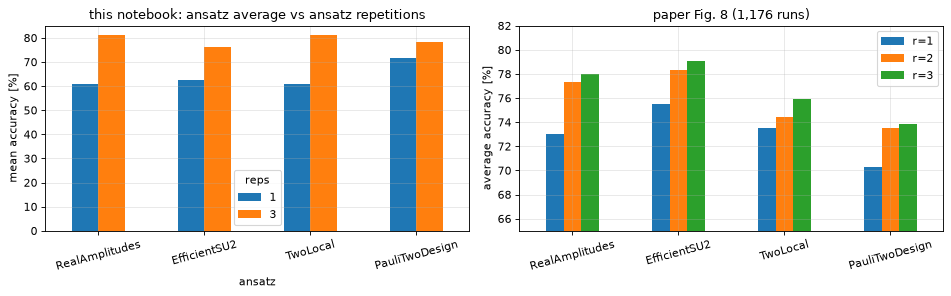

(675 s, 8 VQC runs)


In [23]:
t0 = time.time(); VS = []
for an_name in ["RealAmplitudes", "EfficientSU2", "TwoLocal", "PauliTwoDesign"]:
    for fmn in VQC_SCAN_MAPS:
        for rp in VQC_SCAN_REPS:
            cfg = dict(fm=fmn, q=3, ans=an_name, reps=rp, label=f"scan {fmn}/{an_name}/r{rp}")
            r = run_vqc(cfg, SEEDS[0], "COBYLA", n_train=VQC_SCAN_TRAIN, n_test=VQC_TEST, iters=VQC_SCAN_ITERS)
            VS.append(dict(ansatz=an_name, fm=fmn, reps=rp, acc=r["acc"], f1=r["f1"]))
    RES[:] = [x for x in RES if not (x["kind"] == "vqc" and str(x["key"]).startswith("scan "))]
VS = pd.DataFrame(VS)
fig8 = VS.groupby(["ansatz", "reps"]).acc.mean().unstack().reindex(["RealAmplitudes", "EfficientSU2", "TwoLocal", "PauliTwoDesign"])
display(fig8.round(2).rename(columns=lambda r: f"mean acc, r={r}"))
display(VS.pivot_table(index="ansatz", columns="fm", values="acc", aggfunc="max").round(2).rename_axis("best accuracy per ansatz x feature map (cf. Table XI)"))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
fig8.plot.bar(ax=ax[0], rot=15); ax[0].set_ylabel("mean accuracy [%]"); ax[0].set_title("this notebook: ansatz average vs ansatz repetitions"); ax[0].legend(title="reps")
pd.DataFrame(FIG8, index=["r=1", "r=2", "r=3"]).T.plot.bar(ax=ax[1], rot=15); ax[1].set_ylim(65, 82); ax[1].set_title("paper Fig. 8 (1,176 runs)"); ax[1].set_ylabel("average accuracy [%]")
plt.tight_layout(); plt.show(); print(f"({time.time() - t0:.0f} s, {len(VS)} VQC runs)")

### 4.2 Optimiser comparison (paper Table XII)
The paper compares COBYLA, SPSA, NFT, Nelder-Mead and Powell (200 iterations) on six circuits. Here: the optimisers of `qiskit-machine-learning` on the circuits listed in `VQC_OPT_CFGS`, with the budget of the configuration cell. Gradient-free optimisers are compared at equal iteration counts; SPSA uses two circuit evaluations per iteration.

,configuration,optimizer,acc,F1,paper acc (Table XII),fit time [s],final loss
0,3q Pauli[Y] + RealAmplitudes r=2,COBYLA,79.667,87.474,91.54,193.719,0.538
1,3q Pauli[Y] + RealAmplitudes r=2,NELDER_MEAD,81.000,86.396,88.42,292.949,0.723


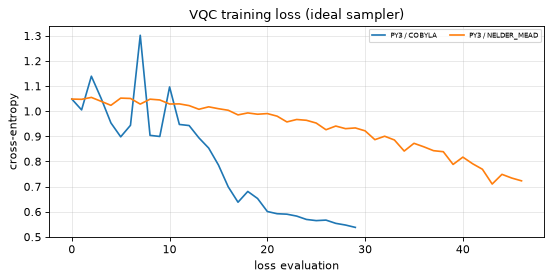

(541 s)


In [24]:
t0 = time.time(); rows = []
for key in VQC_OPT_CFGS:
    cfg = VQC_CFG[key]
    for opt in VQC_OPTIMIZERS:
        r = run_vqc(cfg, SEEDS[0], opt, tag=key)
        rows.append({"configuration": cfg["label"], "optimizer": opt, "acc": r["acc"], "F1": r["f1"], "paper acc (Table XII)": cfg["opt_paper"][opt],
                     "fit time [s]": r["t_fit"], "final loss": r["final_loss"]})
T12 = pd.DataFrame(rows); display(T12.round(3))
fig, ax = plt.subplots(1, 1, figsize=(7, 3.6))
for (k_, o_, b_), h in VQC_HIST.items():
    if b_ == "ideal" and k_ in VQC_OPT_CFGS:
        ax.plot(h, label=f"{k_} / {o_}")
ax.set_title("VQC training loss (ideal sampler)"); ax.set_xlabel("loss evaluation"); ax.set_ylabel("cross-entropy"); ax.legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show(); print(f"({time.time() - t0:.0f} s)")

### 4.3 VQC under device noise (paper Table XIII)
The VQC is **trained** with the noisy sampler (the paper trained on the noisy simulators too), with the circuit transpiled for the fake device. The paper's test rows are the full test set; here a subset (see the configuration cell). The reference "ideal on the same rows" uses the same optimiser, budget, seed and rows.

In [25]:
t0 = time.time(); rows = []
for key, opt in VQC_NOISY_RUNS:
    cfg = VQC_CFG[key]
    ref = run_vqc(cfg, SEEDS[0], opt, n_test=VQC_NOISY_TEST, tag=key)
    paper_row = [pr for k_, o_, pr in VQC_NOISY_PAPER_ROWS if k_ == key and o_ == opt][0]
    for bk in NOISY_BACKENDS:
        r = run_vqc(cfg, SEEDS[0], opt, backend=bk, n_test=VQC_NOISY_TEST, tag=key); r["acc_ideal_ref"] = ref["acc"]
        pn = paper_row[bk]
        rows.append({"configuration": f"{cfg['label']} ({opt})", "backend": bk, "acc": r["acc"], "F1": r["f1"], "paper acc": pn[0], "paper F1": pn[3],
                     "ideal acc, same rows": ref["acc"], "CX": r["cx"], "fit [s]": r["t_fit"]})
        print(f"  {key} {opt} {bk}: acc {r['acc']:.1f} F1 {r['f1']:.1f} ({r['t_fit']:.0f} s)", flush=True)
T13 = pd.DataFrame(rows); display(T13.round(2)); print(f"({time.time() - t0:.0f} s)")

  PY3 COBYLA FakeNairobiV2: acc 75.0 F1 84.8 (85 s)


  PY3 COBYLA FakeLagosV2: acc 75.0 F1 84.8 (82 s)


  PY3 COBYLA FakePerth: acc 75.0 F1 84.8 (62 s)


,configuration,backend,acc,F1,paper acc,paper F1,"ideal acc, same rows",CX,fit [s]
0,3q Pauli[Y] + RealAmplitudes r=2 (COBYLA),FakeNairobiV2,75.0,84.85,90.86,94.08,72.5,4,85.00
1,3q Pauli[Y] + RealAmplitudes r=2 (COBYLA),FakeLagosV2,75.0,84.85,91.57,94.50,72.5,4,82.34
2,3q Pauli[Y] + RealAmplitudes r=2 (COBYLA),FakePerth,75.0,84.85,90.43,93.84,72.5,4,62.27


(424 s)


## 5. Hybrid quantum-classical neural network (paper Section IV-C)

Following the paper's Fig. 7 the network is `n_features -> Linear(64) -> ReLU -> Linear(64) -> ReLU -> Linear(n_qubits) -> quantum layer`. The last linear layer outputs `n_qubits` numbers that are used as the rotation angles of the feature map; the ansatz angles are trainable weights; the network output is the expectation value `<Z...Z>` in `[-1, 1]` and its sign is the predicted class. Gradients flow through the quantum layer, so the classical and the quantum parameters are trained together with Adam. The input of the network is the full numeric feature vector (standardised, no PCA), because the figure shows the classical layers doing the dimension reduction (`# CHOICE`).

**Implementation note.** The paper wires a Qiskit `EstimatorQNN` into PyTorch. With the default parameter-shift gradient this costs about 30 s per 64-sample step on this machine, so the notebook uses a custom `torch.autograd.Function` that evaluates the **same Qiskit circuit** on Aer in one batched call and takes central finite differences for the gradients. The next cell proves that its forward values and both gradients equal those of `EstimatorQNN` (exact estimator, no shot noise).

In [26]:
class QuantumHolder:
    """The circuit of the quantum layer plus an Aer statevector simulator that returns <Z...Z> (batched)."""
    def __init__(self, input_params, weight_params, circuit):
        qc = circuit.copy(); n = qc.num_qubits
        qc.save_expectation_value(SparsePauliOp("Z" * n), list(range(n)), label="zz")
        self.qc, self.params, self.n = qc, list(input_params) + list(weight_params), n
        self.sim = AerSimulator(method="statevector")

class BatchedQuantumLayer(torch.autograd.Function):
    @staticmethod
    def _expect(h, vals):
        res = h.sim.run(h.qc, parameter_binds=[{p: vals[:, j].tolist() for j, p in enumerate(h.params)}]).result()
        return np.array([res.data(i)["zz"] for i in range(len(vals))], dtype=float)
    @staticmethod
    def forward(ctx, x, w, h):
        xs, ws = x.detach().double().numpy(), w.detach().double().numpy()
        out = BatchedQuantumLayer._expect(h, np.concatenate([xs, np.tile(ws, (len(xs), 1))], axis=1))
        ctx.save_for_backward(x, w); ctx.h = h
        return torch.tensor(out, dtype=x.dtype).unsqueeze(1)
    @staticmethod
    def backward(ctx, g):
        x, w = ctx.saved_tensors; h = ctx.h
        xs, ws = x.detach().double().numpy(), w.detach().double().numpy()
        B, q = xs.shape; P = len(ws); eps = 1e-4                                   # central finite differences in double precision
        base = np.concatenate([xs, np.tile(ws, (B, 1))], axis=1); shifted = []
        for j in range(q + P):
            for s in (+1, -1):
                v = base.copy(); v[:, j] += s * eps; shifted.append(v)
        e = BatchedQuantumLayer._expect(h, np.concatenate(shifted, axis=0)).reshape(q + P, 2, B)
        grad = (e[:, 0, :] - e[:, 1, :]) / (2 * eps)
        gout = g.detach().double().numpy().reshape(B)
        return (torch.tensor(grad[:q].T * gout[:, None], dtype=x.dtype),
                torch.tensor((grad[q:] * gout[None, :]).sum(axis=1), dtype=w.dtype), None)

class HybridNet(torch.nn.Module):
    def __init__(self, n_in, q, holder, n_weights, seed):
        super().__init__()
        self.net = torch.nn.Sequential(torch.nn.Linear(n_in, HQNN_HIDDEN), torch.nn.ReLU(), torch.nn.Linear(HQNN_HIDDEN, HQNN_HIDDEN), torch.nn.ReLU(), torch.nn.Linear(HQNN_HIDDEN, q))
        self.w = torch.nn.Parameter(torch.tensor(np.random.default_rng(seed).uniform(-0.1, 0.1, n_weights), dtype=torch.float32))
        self.holder = holder
    def angles(self, x):
        return self.net(x)
    def forward(self, x):
        return BatchedQuantumLayer.apply(self.angles(x), self.w, self.holder)

# equivalence with Qiskit's EstimatorQNN (exact estimator): forward, input gradient and weight gradient
c = HQNN_CFG["HYZ3"]; fm_c = feature_map(c["fm"], c["q"], c["fr"]); an_c = build_ansatz(c["ans"], c["q"], c["ar"]); qc_c = fm_c.compose(an_c)
holder_c = QuantumHolder(fm_c.parameters, an_c.parameters, qc_c)
qnn = EstimatorQNN(circuit=qc_c, input_params=list(fm_c.parameters), weight_params=list(an_c.parameters), observables=SparsePauliOp("Z" * c["q"]),
                   estimator=StatevectorEstimator(default_precision=0.0), default_precision=0.0, input_gradients=True)
xin = rng.uniform(0, math.pi, (4, c["q"])); win = rng.uniform(-0.5, 0.5, an_c.num_parameters)
f_ref = qnn.forward(xin, win); gi_ref, gw_ref = qnn.backward(xin, win)
xt = torch.tensor(xin, dtype=torch.float32, requires_grad=True); wt = torch.tensor(win, dtype=torch.float32, requires_grad=True)
out = BatchedQuantumLayer.apply(xt, wt, holder_c); out.sum().backward()
print("forward max |diff|        :", float(np.abs(out.detach().numpy() - f_ref).max()))
print("input-gradient max |diff| :", float(np.abs(xt.grad.numpy() - gi_ref[:, 0, :]).max()))
print("weight-gradient max |diff|:", float(np.abs(wt.grad.numpy() - gw_ref[:, 0, :].sum(0)).max()))
assert np.allclose(out.detach().numpy(), f_ref, atol=1e-5) and np.allclose(xt.grad.numpy(), gi_ref[:, 0, :], atol=1e-3) and np.allclose(wt.grad.numpy(), gw_ref[:, 0, :].sum(0), atol=1e-3)
print("batched Aer layer == EstimatorQNN (forward and gradients)  ->  OK")

forward max |diff|        : 3.5047102503460437e-07
input-gradient max |diff| : 1.4997043566999935e-06
weight-gradient max |diff|: 4.679812191099586e-07
batched Aer layer == EstimatorQNN (forward and gradients)  ->  OK


In [27]:
class NoisyZZExpectation:
    """<Z...Z> of the quantum layer from 1024 noisy shots on a fake device (circuit transpiled to the device)."""
    def __init__(self, circuit, input_params, weight_params, backend_name, seed):
        qc = circuit.copy(); qc.measure_all()
        self.params = list(input_params) + list(weight_params)
        self.executed = transpile(qc, FAKE[backend_name], optimization_level=1, seed_transpiler=seed)
        self.sim, self.seed, self.cx = noisy_simulator(backend_name), seed, self.executed.count_ops().get("cx", 0)
    def __call__(self, x, w):
        vals = np.concatenate([x, np.tile(w, (len(x), 1))], axis=1); order = {p.name: j for j, p in enumerate(self.params)}
        binds = {p: vals[:, order[p.name]].tolist() for p in self.executed.parameters}
        res = self.sim.run(self.executed, parameter_binds=[binds], shots=SHOTS, seed_simulator=self.seed).result()
        out = []
        for i in range(len(vals)):
            cnt = res.get_counts(i); out.append(sum(v * (-1) ** bin(int(b, 2)).count("1") for b, v in cnt.items()) / SHOTS)
        return np.array(out)

# sanity check of the parity read-out: the transpiled circuit without noise must give the exact <Z...Z> up to shot noise
nz = NoisyZZExpectation(qc_c, fm_c.parameters, an_c.parameters, "FakePerth", SEED)
binds = {p: np.concatenate([xin, np.tile(win, (4, 1))], axis=1)[:, {q_.name: j for j, q_ in enumerate(nz.params)}[p.name]].tolist() for p in nz.executed.parameters}
cnt = AerSimulator(method="statevector").run(nz.executed, parameter_binds=[binds], shots=20000, seed_simulator=3).result()
par = np.array([sum(v * (-1) ** bin(int(b, 2)).count("1") for b, v in cnt.get_counts(i).items()) / 20000 for i in range(4)])
print("noiseless transpiled parity read-out vs exact:", np.round(par, 3), np.round(f_ref.ravel(), 3)); assert np.abs(par - f_ref.ravel()).max() < 0.03

HQ_HIST = {}
def run_hqnn(key, seed, backends):
    c = HQNN_CFG[key]; y = DATA["y"]; tr, te = make_split(seed)
    Ftr, Fte = prep_full(tr, te)
    s_tr = take(np.arange(len(tr)), y[tr], HQNN_TRAIN, seed); s_te = take(np.arange(len(te)), y[te], HQNN_TEST, seed)
    fm = feature_map(c["fm"], c["q"], c["fr"]); an = build_ansatz(c["ans"], c["q"], c["ar"]); qc = fm.compose(an)
    holder = QuantumHolder(fm.parameters, an.parameters, qc)
    torch.manual_seed(seed); net = HybridNet(Ftr.shape[1], c["q"], holder, an.num_parameters, seed)
    opt = torch.optim.Adam(net.parameters(), lr=HQNN_LR)
    Xt = torch.tensor(Ftr[s_tr], dtype=torch.float32); Yt = torch.tensor(2.0 * y[tr][s_tr] - 1, dtype=torch.float32).unsqueeze(1)
    g = np.random.default_rng(seed); losses = []; t0 = time.time()
    for ep in range(HQNN_EPOCHS):
        perm = g.permutation(len(Xt)); tot = 0.0
        for i in range(0, len(Xt), HQNN_BATCH):
            b = perm[i:i + HQNN_BATCH]; opt.zero_grad()
            loss = torch.nn.functional.mse_loss(net(Xt[b]), Yt[b]); loss.backward(); opt.step(); tot += float(loss) * len(b)
        losses.append(tot / len(Xt))
    t_fit = time.time() - t0
    HQ_HIST[key] = losses
    with torch.no_grad():
        Xe = torch.tensor(Fte[s_te], dtype=torch.float32); out = net(Xe).numpy().ravel()
    pred = (out > 0).astype(int); ye = y[te][s_te]
    small = slice(0, HQNN_NOISY_TEST)
    row = log(kind="hqnn", model="HQNN", key=key, backend="ideal", seed=seed, n_train=len(s_tr), n_test=len(s_te), epochs=HQNN_EPOCHS,
              cx=transpile(qc.decompose(reps=4), FAKE["FakePerth"], optimization_level=1, seed_transpiler=seed).count_ops().get("cx", 0), t_fit=t_fit, final_loss=losses[-1],
              acc_small=100 * accuracy_score(ye[small], pred[small]), **metrics(ye, pred))
    print(f"  {key} ideal: acc {row['acc']:.1f} F1 {row['f1']:.1f} loss {losses[0]:.3f}->{losses[-1]:.3f} ({t_fit:.0f} s)", flush=True)
    with torch.no_grad():
        z = net.angles(torch.tensor(Fte[s_te][small], dtype=torch.float32)).double().numpy(); w = net.w.detach().double().numpy()
    for bk in backends:
        nzz = NoisyZZExpectation(qc, fm.parameters, an.parameters, bk, seed)
        t1 = time.time(); e = nzz(z, w); pn = (e > 0).astype(int)
        r2 = log(kind="hqnn", model="HQNN", key=key, backend=bk, seed=seed, n_train=len(s_tr), n_test=len(pn), epochs=HQNN_EPOCHS, cx=nzz.cx,
                 t_fit=t_fit, t_pred=time.time() - t1, acc_ideal_ref=row["acc_small"], **metrics(ye[small], pn))
        print(f"      noisy {bk}: acc {r2['acc']:.1f} F1 {r2['f1']:.1f} (ideal on the same rows {row['acc_small']:.1f}; CX {nzz.cx})", flush=True)
    return row

noiseless transpiled parity read-out vs exact: [-0.201  0.869 -0.756 -0.139] [-0.196  0.865 -0.758 -0.144]


### 5.1 Training and evaluation (paper Tables XIV and XV)
The network is trained on the ideal simulator and then **evaluated** on the noisy ones (the paper does not say how it handled the cost of training under noise; hybrid training times of up to 80 hours are mentioned in the same authors' journal paper). The "ideal" rows use `HQNN_TEST` test rows, the noisy rows the first `HQNN_NOISY_TEST` of them.

  HZY5 ideal: acc 87.8 F1 91.7 loss 0.939->0.674 (33 s)


      noisy FakeNairobiV2: acc 87.5 F1 91.2 (ideal on the same rows 90.0; CX 42)


      noisy FakeLagosV2: acc 50.0 F1 60.0 (ideal on the same rows 90.0; CX 42)


      noisy FakePerth: acc 92.5 F1 94.7 (ideal on the same rows 90.0; CX 42)


,configuration,backend,acc,F1,paper acc,paper F1,train rows,test rows,CX,train [s]
0,5q Pauli[ZY] + EfficientSU2 r=1,ideal,87.75,91.74,95.4,96.9,128,400,42,33.49
1,5q Pauli[ZY] + EfficientSU2 r=1,FakeNairobiV2,87.50,91.23,90.0,85.9,128,40,42,33.49
2,5q Pauli[ZY] + EfficientSU2 r=1,FakeLagosV2,50.00,60.00,86.8,80.3,128,40,42,33.49
3,5q Pauli[ZY] + EfficientSU2 r=1,FakePerth,92.50,94.74,94.2,92.4,128,40,42,33.49


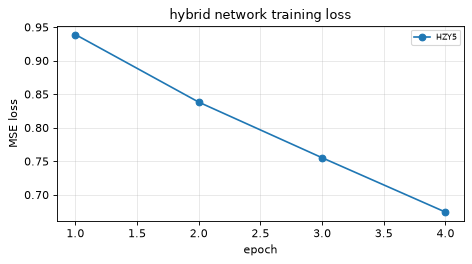

(51 s)


In [28]:
t0 = time.time()
for key in HQNN_CFGS:
    run_hqnn(key, SEEDS[0], NOISY_BACKENDS)
rows = []
for r in RES:
    if r["kind"] == "hqnn":
        c = HQNN_CFG[r["key"]]
        if r["backend"] == "ideal":
            pa, pf = c["ideal"][0], c["ideal"][3]
        else:
            pn = c["noisy"][r["backend"]] if c["noisy"] else None
            pa, pf = (pn[0], pn[3]) if pn else (np.nan, np.nan)
        rows.append({"configuration": c["label"], "backend": r["backend"], "acc": r["acc"], "F1": r["f1"], "paper acc": pa, "paper F1": pf,
                     "train rows": r["n_train"], "test rows": r["n_test"], "CX": r["cx"], "train [s]": r["t_fit"]})
T14 = pd.DataFrame(rows); display(T14.round(2))
fig, ax = plt.subplots(1, 1, figsize=(6, 3.4))
for key, h in HQ_HIST.items():
    ax.plot(range(1, len(h) + 1), h, "-o", label=key)
ax.set_xlabel("epoch"); ax.set_ylabel("MSE loss"); ax.set_title("hybrid network training loss"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()
print(f"({time.time() - t0:.0f} s)")

## 6. Noise versus circuit complexity and timing (paper Section IV-A-4, V)

The paper explains the differences between the three fake devices by the CNOT count of the circuits and by each device's error profile (FakeLagos: good single-qubit gates but poor CNOTs and readout; FakeNairobi / FakePerth the opposite). The notebook has far fewer noisy runs than the paper, so the same information is drawn as a **scatter of F1 against CNOT count** (one point per noisy run), and the accuracy change against the ideal run on the same rows is tabulated per model and backend.

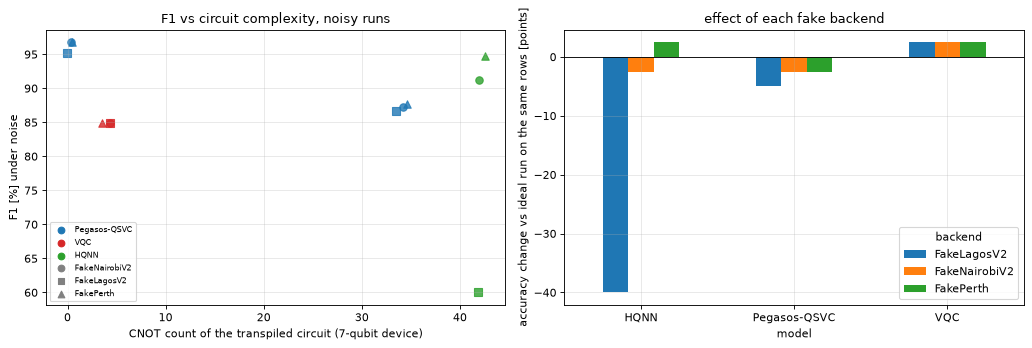

,model,key,backend,cx,n_test,acc,acc_ideal_ref,f1,drop
0,Pegasos-QSVC,Z5r1,FakeNairobiV2,0,40,95.0,95.0,96.77,0.0
1,Pegasos-QSVC,Z5r1,FakeLagosV2,0,40,92.5,95.0,95.24,-2.5
2,Pegasos-QSVC,Z5r1,FakePerth,0,40,95.0,95.0,96.77,0.0
3,Pegasos-QSVC,ZYY4r1,FakeNairobiV2,34,40,82.5,87.5,87.27,-5.0
4,Pegasos-QSVC,ZYY4r1,FakeLagosV2,34,40,80.0,87.5,86.67,-7.5
5,Pegasos-QSVC,ZYY4r1,FakePerth,34,40,82.5,87.5,87.72,-5.0
6,VQC,PY3,FakeNairobiV2,4,40,75.0,72.5,84.85,2.5
7,VQC,PY3,FakeLagosV2,4,40,75.0,72.5,84.85,2.5
8,VQC,PY3,FakePerth,4,40,75.0,72.5,84.85,2.5
9,HQNN,HZY5,FakeNairobiV2,42,40,87.5,90.0,91.23,-2.5


In [29]:
noisy = pd.DataFrame([r for r in RES if r["kind"] in ("qsvc", "vqc", "hqnn") and r["backend"] != "ideal" and "acc_ideal_ref" in r])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
mk = {"FakeNairobiV2": "o", "FakeLagosV2": "s", "FakePerth": "^"}; col = {"Pegasos-QSVC": "tab:blue", "VQC": "tab:red", "HQNN": "tab:green"}
jit = np.random.default_rng(SEED)
for _, r in noisy.iterrows():
    ax[0].scatter(r["cx"] + jit.uniform(-0.6, 0.6), r["f1"], marker=mk[r["backend"]], color=col[r["model"]], alpha=0.8, s=45)
for m_, c_ in col.items():
    ax[0].scatter([], [], color=c_, label=m_)
for b_, m__ in mk.items():
    ax[0].scatter([], [], marker=m__, color="gray", label=b_)
ax[0].set_xlabel("CNOT count of the transpiled circuit (7-qubit device)"); ax[0].set_ylabel("F1 [%] under noise"); ax[0].set_title("F1 vs circuit complexity, noisy runs"); ax[0].legend(fontsize=7)
noisy["drop"] = noisy["acc"] - noisy["acc_ideal_ref"]
d = noisy.groupby(["model", "backend"])["drop"].mean().unstack()
d.plot.bar(ax=ax[1], rot=0); ax[1].set_ylabel("accuracy change vs ideal run on the same rows [points]"); ax[1].set_title("effect of each fake backend"); ax[1].axhline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()
display(noisy[["model", "key", "backend", "cx", "n_test", "acc", "acc_ideal_ref", "f1", "drop"]].round(2))

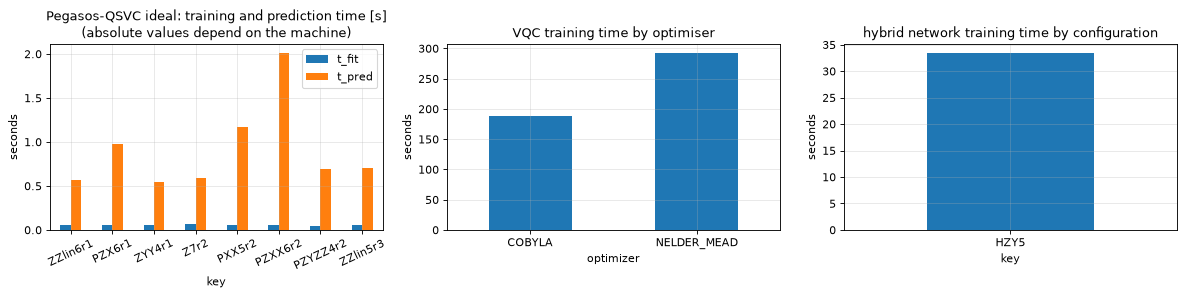

mean training time per model [s]:  Pegasos-QSVC 0.1 | VQC 223.5 | HQNN 33.5   (budgets differ: see configuration cell)


In [30]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
q_ = pd.DataFrame([r for r in RES if r["kind"] == "qsvc" and r["backend"] == "ideal" and r["n_test"] >= min(5000, IDEAL_N_TEST or 5000) and r["C"] == 1000 and r["steps"] == 100])
if len(q_):
    g = q_.groupby("key")[["t_fit", "t_pred"]].mean().reindex([k for k in QSVC_NOISELESS if k in set(q_.key)])
    g.plot.bar(ax=ax[0], rot=25); ax[0].set_title("Pegasos-QSVC ideal: training and prediction time [s]\n(absolute values depend on the machine)"); ax[0].set_ylabel("seconds")
v_ = pd.DataFrame([r for r in RES if r["kind"] == "vqc" and r["backend"] == "ideal" and r["key"] in VQC_OPT_CFGS])
if len(v_):
    v_.groupby("optimizer")["t_fit"].mean().plot.bar(ax=ax[1], rot=0); ax[1].set_title("VQC training time by optimiser"); ax[1].set_ylabel("seconds")
h_ = pd.DataFrame([r for r in RES if r["kind"] == "hqnn" and r["backend"] == "ideal"])
h_.groupby("key")["t_fit"].mean().plot.bar(ax=ax[2], rot=0); ax[2].set_title("hybrid network training time by configuration"); ax[2].set_ylabel("seconds")
plt.tight_layout(); plt.show()
print("mean training time per model [s]:  Pegasos-QSVC %.1f | VQC %.1f | HQNN %.1f   (budgets differ: see configuration cell)" % (q_.t_fit.mean(), v_.t_fit.mean(), h_.t_fit.mean()))

## 7. Optional: one real-hardware cell

The paper deliberately ran **no** job on a real quantum computer ("we did not test our proposed methods on actual devices"). So there is no hardware number to reproduce. If you put an IBM Quantum token in `IBM_TOKEN` (or in Colab Secrets as `IBM_TOKEN`) the next cell estimates a small block of kernel entries of the headline circuit (5-qubit `ZFeatureMap`) on the least busy real device and compares them with the exact and the fake-backend values. It is skipped when no token is given. This cell was written against the `qiskit-ibm-runtime` 0.50 API but could not be executed in the environment where this notebook was produced (no token).

In [31]:
IBM_TOKEN_USED = IBM_TOKEN or os.environ.get("IBM_TOKEN", "")
if not IBM_TOKEN_USED:
    try:
        from google.colab import userdata
        IBM_TOKEN_USED = userdata.get("IBM_TOKEN") or ""
    except Exception:
        pass
if not IBM_TOKEN_USED:
    print("IBM_TOKEN not set: real-hardware cell skipped (the paper has no hardware numbers either).")
else:
    try:
        from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
        service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN_USED)
        dev = service.least_busy(operational=True, simulator=False, min_num_qubits=5)
        print("real device:", dev.name)
        c = QSVC_CFG["Z5r1"]; fm = feature_map(c["fm"], c["q"], c["r"]); kn_hw = NoisyFidelityKernel(fm, "FakePerth")
        tr, te = make_split(SEEDS[0]); Ztr, Zte = prep(tr, te, c["q"], AMAX)
        A, B = Zte[:4], Ztr[:4]
        pm = generate_preset_pass_manager(optimization_level=1, backend=dev, seed_transpiler=SEED)
        circ_hw = pm.run(kn_hw.logical)
        names = [f"a{i:02d}" for i in range(5)] + [f"b{i:02d}" for i in range(5)]
        pubs = []
        for a in A:
            for b in B:
                vals = dict(zip(names, np.concatenate([a, b])))
                pubs.append((circ_hw, [vals[p.name] for p in circ_hw.parameters]))
        job = SamplerV2(mode=dev).run(pubs, shots=SHOTS); res = job.result()
        K_hw = np.array([res[i].data.meas.get_counts().get("0" * 5, 0) / SHOTS for i in range(len(pubs))]).reshape(4, 4)
        K_id = BatchedStatevectorKernel(fm).evaluate(A, B)
        print("mean |K_hardware - K_ideal| =", float(np.abs(K_hw - K_id).mean()))
    except Exception as e:
        print("real-hardware cell failed (check token, channel and plan):", repr(e)[:200])

IBM_TOKEN not set: real-hardware cell skipped (the paper has no hardware numbers either).


## 8. Side-by-side comparison with the paper

Every checkable claim gets a verdict: **reproduced** (within 2 accuracy points / 2 F1 points), **not reached** or **exceeded** (with the gap in points), or **cannot be checked** (no counterpart in this run). Qualitative claims are judged from the notebook's own numbers. The small test subsets used for the noisy runs carry a sampling error of several points (a 30-row subset has a binomial standard error above 5 points), so the noisy verdicts are weak evidence: whenever the 95 % binomial interval of a subset is wider than the 2-point tolerance, the claim is never called "reproduced"; if the gap lies inside the interval the verdict reads "within sampling error", otherwise "not reached" / "exceeded".

In [32]:
def verdict(paper, mine, tol=TOL, n=None):
    if paper is None or (isinstance(paper, float) and np.isnan(paper)):
        return "cannot be checked (no paper value)"
    if mine is None or (isinstance(mine, float) and np.isnan(mine)):
        return "cannot be checked (not run in this mode)"
    dlt = mine - paper
    if n:                                                  # a test subset of n rows: is the 95 % binomial interval wider than the 2-point tolerance?
        half = 196 * math.sqrt(max(mine / 100 * (1 - mine / 100), 1e-4) / n)
        if half > tol:                                     # then the subset cannot resolve a 2-point difference: never call it "reproduced"
            if abs(dlt) <= half:
                return f"within sampling error (n={n}, +-{half:.1f}; {dlt:+.1f})"
            return f"not reached ({dlt:+.1f})" if dlt < 0 else f"exceeded ({dlt:+.1f})"
    if abs(dlt) <= tol:
        return "reproduced"
    return f"not reached ({dlt:+.1f})" if dlt < 0 else f"exceeded ({dlt:+.1f})"
CL = []
def claim(group, text, paper, mine, n=None):
    CL.append(dict(group=group, claim=text, paper=paper, notebook=mine, verdict=verdict(paper, mine, n=n)))

# Table II
for C in C_SWEEP:
    r = qmean(TABLE2_CIRCUIT, C=C)
    claim("T-II C sweep", f"Pegasos-QSVC accuracy, C={C} (5q ZFeatureMap r=1 assumed)", TABLE2[C][0], r["acc"])
# Table III
for _, r in T3.iterrows():
    claim("T-III ideal QSVC", f"{r['configuration']}: accuracy", r["paper acc"], r["acc"])
    claim("T-III ideal QSVC", f"{r['configuration']}: F1", r["paper F1"], r["F1"])
# Table X
for key in QSVC_NOISY:
    for bk in NOISY_BACKENDS:
        r = run_qsvc(key, SEEDS[0], steps=NOISY_STEPS, backend=bk, n_test=NOISY_N_TEST); pn = QSVC_NOISY_PAPER[key][bk]
        claim("T-X noisy QSVC", f"{QSVC_CFG[key]['label']}, {bk}: accuracy", pn[0], r["acc"], n=NOISY_N_TEST)
        fc, note = corrected_f1(pn)
        claim("T-X noisy QSVC", f"{QSVC_CFG[key]['label']}, {bk}: F1 ({note})", fc, r["f1"], n=NOISY_N_TEST)
# Table XII
for _, r in T12.iterrows():
    claim("T-XII VQC optimisers", f"VQC {r['configuration']}, {r['optimizer']}: accuracy", r["paper acc (Table XII)"], r["acc"], n=VQC_TEST)
# Table XIII
for _, r in T13.iterrows():
    claim("T-XIII noisy VQC", f"VQC {r['configuration']}, {r['backend']}: accuracy", r["paper acc"], r["acc"], n=VQC_NOISY_TEST)
    claim("T-XIII noisy VQC", f"VQC {r['configuration']}, {r['backend']}: F1", r["paper F1"], r["F1"], n=VQC_NOISY_TEST)
# Tables XIV / XV
for _, r in T14.iterrows():
    tag = "T-XIV HQNN ideal" if r["backend"] == "ideal" else "T-XV HQNN noisy"
    claim(tag, f"HQNN {r['configuration']}, {r['backend']}: accuracy", r["paper acc"], r["acc"], n=int(r["test rows"]))
    claim(tag, f"HQNN {r['configuration']}, {r['backend']}: F1", r["paper F1"], r["F1"], n=int(r["test rows"]))
for key in HQNN_CFG:
    if key not in HQNN_CFGS:
        CL.append(dict(group="T-XIV HQNN ideal", claim=f"HQNN {HQNN_CFG[key]['label']}: accuracy", paper=HQNN_CFG[key]["ideal"][0], notebook=None, verdict="cannot be checked (not run in this mode)"))
# Tables XVI / XVII and the abstract: best configuration per model
ideal_rows = [r for r in RES if r["kind"] in ("qsvc", "vqc", "hqnn") and r["backend"] == "ideal"]
def best(model, noisy_, min_n=0):
    rr = [r for r in RES if r["kind"] in ("qsvc", "vqc", "hqnn") and r["model"] == model and ((r["backend"] != "ideal") == noisy_) and r["n_test"] >= min_n
          and not str(r["key"]).startswith("scan") and (noisy_ or r.get("steps", 100) == 100) and (model != "Pegasos-QSVC" or r["C"] == 1000)]
    return max(rr, key=lambda r: r["acc"]) if rr else None
for model in ["Pegasos-QSVC", "VQC", "HQNN"]:
    b = best(model, False, 200)
    if model == "Pegasos-QSVC":          # best configuration of Table III by its mean accuracy over the model seeds (not the luckiest single seed)
        claim("T-XVI best, no noise", f"best {model} (accuracy, best of the Table III configurations, mean over model seeds)", T16[model][0], float(T3["acc"].max()))
    else:
        claim("T-XVI best, no noise", f"best {model} (accuracy)", T16[model][0], b["acc"] if b else None, n=b["n_test"] if b else None)
    b = best(model, True)
    claim("T-XVII best, noisy", f"best {model} (accuracy)", T17[model][0], b["acc"] if b else None, n=b["n_test"] if b else None)
z5 = [r for r in RES if r["kind"] == "qsvc" and r["key"] == "Z5r1" and r["backend"] != "ideal"]
if z5:
    claim("abstract", "Pegasos-QSVC 5q ZFeatureMap r=1 under noise: accuracy 93.05 % (mean over the fake backends run)", 93.05, float(np.mean([r["acc"] for r in z5])), n=NOISY_N_TEST)
    claim("abstract", "same circuit: F1 93.73 % (as printed in the abstract and Table X)", 93.73, float(np.mean([r["f1"] for r in z5])), n=NOISY_N_TEST)
    claim("abstract", "same circuit: F1 95.43 % (the value that is consistent with the printed recall; printed as precision)", 95.43, float(np.mean([r["f1"] for r in z5])), n=NOISY_N_TEST)

In [33]:
# qualitative claims, judged from the notebook's own numbers
def qual(text, paper, mine, ok):
    CL.append(dict(group="qualitative", claim=text, paper=paper, notebook=mine, verdict=("reproduced" if ok else "not reproduced") if ok is not None else "cannot be checked (not run in this mode)"))

nz_ = noisy.dropna(subset=["acc_ideal_ref"]); md_ = nz_["acc"].sub(nz_["acc_ideal_ref"]).mean()
qual("noise lowers accuracy relative to the ideal run on the same rows (mean change over all noisy runs, points)", "< 0", round(md_, 2), md_ < 0)
# C sweep collapse
lo_ = qmean(TABLE2_CIRCUIT, C=min(C_SWEEP)); hi_ = qmean(TABLE2_CIRCUIT, C=1000)
qual("a large C is needed: C=1000 clearly better than the smallest C run, which collapses to 'attack for everything' (recall 100 %, accuracy = attack share)",
     "92.25 vs 74.56 (recall 100)", f"{hi_['acc']:.1f} vs {lo_['acc']:.1f} (recall {lo_['rec']:.0f})", hi_["acc"] - lo_["acc"] > 5 and lo_["rec"] > 99)
qual("the all-attack accuracy of the preprocessed table equals the paper's 74.56 %", 74.56, round(100 * DATA["y"].mean(), 2), abs(100 * DATA["y"].mean() - 74.56) < 0.5)
a20 = STEPS_TAB.set_index("steps").acc
if 100 in a20.index and 20 in a20.index:
    big = [s for s in a20.index if s > 100]
    qual("100 steps are enough: accuracy at 100 steps well above 20 steps, and more steps (if run) add less than 1 point", "100 best trade-off",
         f"20: {a20[20]:.1f}, 100: {a20[100]:.1f}" + (f", {max(big)}: {a20[max(big)]:.1f}" if big else ""), a20[100] - a20[20] > 3 and (not big or a20[max(big)] - a20[100] < 1.0))
# scan claims
g_q = SC.groupby("q").acc.mean()
lowq, midq = g_q[g_q.index <= 3].mean(), g_q[(g_q.index >= 5) & (g_q.index <= 7)].mean()
qual("accuracy is poor for 2-3 qubits and higher for 5-7 qubits (mean over the scanned maps and reps)", "rises, saturates at 6-7", f"q<=3: {lowq:.1f}, q=5-7: {midq:.1f}", midq > lowq)
if max(SCAN_QUBITS) >= 9:
    hiq = g_q[g_q.index >= 8].mean()
    qual("saturation: 8-10 qubits are not better than 6-7 qubits (within 1 point)", "plateau after 6-7", f"q=6-7: {g_q[(g_q.index >= 6) & (g_q.index <= 7)].mean():.1f}, q>=8: {hiq:.1f}", hiq - g_q[(g_q.index >= 6) & (g_q.index <= 7)].mean() < 1.0)
else:
    qual("saturation: 8-10 qubits are not better than 6-7 qubits", "plateau after 6-7", "qubits above 7 not scanned", None)
pk = SC[SC.q >= 4].groupby("r").acc.agg(["std", "max", "mean"])
if len(pk) >= 2:
    qual("more repetitions make the results more stable (smaller spread of accuracy over maps and qubits >= 4) without a much higher peak (< 2 points)", "stability up, peak flat",
         f"std r=min: {pk['std'].iloc[0]:.2f}, r=max: {pk['std'].iloc[-1]:.2f}; peak {pk['max'].iloc[0]:.1f} vs {pk['max'].iloc[-1]:.1f}", (pk["std"].iloc[-1] <= pk["std"].iloc[0]) and (pk["max"].iloc[-1] - pk["max"].iloc[0] < 2.0))
zz = SC[SC.fm.str.startswith("ZZ-") & (SC.q >= 4)].groupby(["fm", "r"]).acc.mean().unstack()
if {"ZZ-linear", "ZZ-full"} <= set(zz.index):
    low_r = [c_ for c_ in zz.columns if c_ <= 2]
    qual("ZZFeatureMap with full entanglement beats linear entanglement at 1-2 repetitions (mean over qubits >= 4)", "full > linear for r<=2",
         f"full {zz.loc['ZZ-full', low_r].mean():.1f} vs linear {zz.loc['ZZ-linear', low_r].mean():.1f}", zz.loc["ZZ-full", low_r].mean() > zz.loc["ZZ-linear", low_r].mean())
else:
    qual("ZZFeatureMap with full entanglement beats linear entanglement at 1-2 repetitions", "full > linear for r<=2", "ZZ maps not both scanned", None)
rank = SC[SC.q >= 4].groupby("fm").acc.mean().sort_values(ascending=False)
if "Z,YY" in rank.index:
    qual("the Pauli map [Z,YY] ranks among the best feature maps (top 4 by mean accuracy over qubits >= 4)", "consistently top", f"rank {list(rank.index).index('Z,YY') + 1} of {len(rank)}", list(rank.index).index("Z,YY") < 4)
noent = [m_ for m_ in ["X", "Y", "Z"] if m_ in set(SC.fm)]; ent = [m_ for m_ in set(SC.fm) if m_ not in ("X", "Y", "Z")]
if noent and ent:
    s_ne = SC[SC.fm.isin(noent) & (SC.q >= 4)].groupby("fm").acc.std().mean(); s_en = SC[SC.fm.isin(ent) & (SC.q >= 4)].groupby("fm").acc.std().mean()
    qual("entanglement-free maps (X, Y, Z) are less stable than entangled maps (std of accuracy over qubits >= 4 and reps)", "less stable", f"std no-entanglement {s_ne:.2f} vs entangled {s_en:.2f}", s_ne > s_en)
# VQC claims
rk = fig8.mean(axis=1).sort_values(ascending=False)
qual("VQC ansatz ranking: EfficientSU2 best on average, PauliTwoDesign worst (Fig. 8; tiny budget here)", "EffSU2 > RealAmp > TwoLocal > PauliTwoDesign", " > ".join(rk.index), rk.index[0] == "EfficientSU2" and rk.index[-1] == "PauliTwoDesign")
qual("VQC accuracy rises with the number of ansatz repetitions (mean over ansatz, first vs last repetition count)", "75.5 -> 79.1 (EffSU2)", f"{fig8.iloc[:, 0].mean():.1f} -> {fig8.iloc[:, -1].mean():.1f}", fig8.iloc[:, -1].mean() > fig8.iloc[:, 0].mean())
ob = T12.groupby("optimizer").acc.mean().sort_values(ascending=False)
qual("COBYLA is among the best optimisers (mean accuracy over the circuits run)", "COBYLA generally highest", ", ".join(f"{k} {v:.1f}" for k, v in ob.items()), list(ob.index).index("COBYLA") < max(1, len(ob) // 2) if "COBYLA" in ob.index else None)
# noise claims
kb = KN.groupby("backend")["mean_abs_err"].mean(); worst = kb.idxmax()
qual("FakeLagos is the most noise-sensitive backend (kernel level: mean |K_noisy - K_ideal| over the circuits, 8x8 real row pairs)", "FakeLagos worst", str({k: round(float(v), 3) for k, v in kb.items()}), worst == "FakeLagosV2")
kc = KN[KN.backend == "FakeLagosV2"].set_index("circuit")["mean_abs_err"]; kp = KN[KN.backend == "FakePerth"].set_index("circuit")["mean_abs_err"]
zl = QSVC_CFG["Z5r1"]["label"]
qual("the Lagos-vs-Perth gap is larger for the CNOT-heavy circuits than for the CNOT-free ZFeatureMap (kernel level)", "Lagos worse with many CX", str({k: round(float(v), 3) for k, v in (kc - kp).items()}), (kc - kp).drop(zl).mean() > (kc - kp)[zl])
zr = [r for r in RES if r["kind"] == "qsvc" and r["key"] == "Z5r1" and r["backend"] != "ideal"]
if zr:
    ref_ = run_qsvc("Z5r1", SEEDS[0], steps=NOISY_STEPS, n_test=NOISY_N_TEST)["acc"]
    qual("the entanglement-free ZFeatureMap keeps its accuracy under noise on all backends run (|change| <= 5 points on the same rows)", "Z map robust", f"ideal {ref_:.1f}; noisy {[round(r['acc'], 1) for r in zr]}", all(abs(r["acc"] - ref_) <= 5 for r in zr))
# model comparison
bq, bv, bh = best("Pegasos-QSVC", True), best("VQC", True), best("HQNN", True)
if bq and bv and bh:
    qual("under noise Pegasos-QSVC is the best purely quantum model (higher accuracy than VQC)", "93.05 vs 91.57", f"{bq['acc']:.1f} vs {bv['acc']:.1f}", bq["acc"] > bv["acc"])
tq, tv, th = q_.t_fit.mean(), v_.t_fit.mean(), h_.t_fit.mean()
qual("Pegasos-QSVC trains faster than VQC and HQNN (mean training time, s; budgets differ)", "QSVC fastest", f"{tq:.1f} / {tv:.1f} / {th:.1f}", tq < min(tv, th))
CL.append(dict(group="timing", claim="absolute training times of the paper", paper="see paper", notebook="see timing figure", verdict="cannot be checked (different hardware and budgets)"))
CL.append(dict(group="hardware", claim="any result on real IBM quantum hardware", paper="none reported", notebook="optional cell, skipped without token", verdict="cannot be checked (paper has no hardware numbers)"))
CMP = pd.DataFrame(CL)
pd.set_option("display.max_colwidth", 120, "display.width", 250, "display.max_rows", 500)
print(CMP.assign(paper=CMP.paper.map(lambda v: round(v, 2) if isinstance(v, float) else v), notebook=CMP.notebook.map(lambda v: round(v, 2) if isinstance(v, float) else v)).to_string(index=False))

               group                                                                                                                                                  claim                                        paper                                                                                  notebook                                            verdict
        T-II C sweep                                                                                             Pegasos-QSVC accuracy, C=1000 (5q ZFeatureMap r=1 assumed)                                        92.25                                                                                     88.43                                 not reached (-3.8)
        T-II C sweep                                                                                              Pegasos-QSVC accuracy, C=100 (5q ZFeatureMap r=1 assumed)                                        91.61                                                                    

In [34]:
cat = CMP.verdict.map(lambda v: "reproduced" if v.startswith("reproduced") else "within sampling error" if v.startswith("within") else "not reached" if v.startswith("not reached")
                      else "exceeded" if v.startswith("exceeded") else "cannot be checked" if v.startswith("cannot") else "not reproduced (qualitative)")
print("verdict counts over all rows of the table:"); print(cat.value_counts().to_string())
print("\nper group:"); print(pd.crosstab(CMP.group, cat).to_string())
print("\nTable X consistency check: is the printed F1 the harmonic mean of the printed precision and recall? (If not, test whether precision and F1 are interchanged.)")
rows = []
for key, d_ in QSVC_NOISY_PAPER.items():
    for bk, v in d_.items():
        fc, note = corrected_f1(v)
        rows.append({"circuit": QSVC_CFG[key]["label"], "backend": bk, "acc": v[0], "printed precision": v[1], "recall": v[2], "printed F1": v[3],
                     "HM(printed P, R)": round(hm(v[1], v[2]), 2), "HM(printed F1, R)": round(hm(v[3], v[2]), 2), "verdict": note})
TX = pd.DataFrame(rows); display(TX[TX["verdict"] != "as printed"].drop_duplicates(["circuit", "printed F1"]))
# the same check through the accuracy: with a prevalence of attacks of 74.5 %, accuracy, recall and precision determine each other
prev = DATA["y"].mean(); v = QSVC_NOISY_PAPER["Z5r1"]["FakePerth"]
tp = prev * v[2] / 100; fn = prev - tp; fp = (1 - prev) - ((v[0] / 100) - tp)      # accuracy = tp + tn
print(f"headline row (5q ZFeatureMap, r=1): accuracy {v[0]} % and recall {v[2]} % at an attack share of {100 * prev:.2f} % imply precision {100 * tp / (tp + fp):.2f} % and F1 {100 * 2 * tp / (2 * tp + fp + fn):.2f} %, "
      f"i.e. the printed 'F1 = 93.73 %' is the precision and the printed 'precision = 95.43 %' is the F1.")

verdict counts over all rows of the table:
verdict
not reached                     30
within sampling error           24
reproduced                      15
cannot be checked                8
not reproduced (qualitative)     5

per group:
verdict               cannot be checked  not reached  not reproduced (qualitative)  reproduced  within sampling error
group                                                                                                                
T-II C sweep                          0            1                             0           3                      0
T-III ideal QSVC                      0           16                             0           0                      0
T-X noisy QSVC                        0            0                             0           0                     12
T-XII VQC optimisers                  0            2                             0           0                      0
T-XIII noisy VQC                      0            3  

,circuit,backend,acc,printed precision,recall,printed F1,"HM(printed P, R)","HM(printed F1, R)",verdict
0,q=6 Pauli[ZX] r=1,FakeNairobiV2,93.03,95.42,97.17,93.71,96.29,95.41,printed precision and F1 interchanged
6,q=5 ZFeatureMap r=1,FakeNairobiV2,93.05,95.43,97.18,93.73,96.30,95.42,printed precision and F1 interchanged
19,q=5 ZZ(Linear) r=3,FakeLagosV2,92.11,94.83,97.08,92.68,95.94,94.83,printed precision and F1 interchanged


headline row (5q ZFeatureMap, r=1): accuracy 93.05 % and recall 97.18 % at an attack share of 74.53 % imply precision 93.73 % and F1 95.42 %, i.e. the printed 'F1 = 93.73 %' is the precision and the printed 'precision = 95.43 %' is the F1.


## 9. Reading the paper critically

**What this reproduction supports.**
* **The data pipeline can be recovered from the text.** Removing the identifier columns and the duplicate rows gives 93,925 flows whose all-attack accuracy is 74.53 %, against 74.56 % in the paper's Table II (76.31 % on the raw file). That is hard to get by chance and indicates that the authors' table is the de-duplicated one.
* **Table II's signature behaviour holds.** Pegasos-QSVC needs a large `C`: with `C=1` the model collapses to "everything is an attack" (74.52 %, recall 100 %, the all-attack accuracy), `C=10` gives about 81 % (paper 79.2 %), and `C=100` / `C=1000` give 89.7 % / 88.4 % (paper 91.6 % / 92.3 %, a gap of 2 to 4 points). Twenty steps are clearly too few (83 %), 100 steps reach 88 %.
* **Feature maps.** In the thin slice of the scan, `Pauli[Z,YY]` is the best of the five maps on average (as in the paper), 5 to 7 qubits beat 3 qubits, and the best single configuration is a `ZZFeatureMap` (full entanglement, 7 qubits) with about 90.6 %.
* **Noise.** At the kernel level `FakeLagosV2` distorts the kernel about 2.5 times more than the other two snapshots (mean |K_noisy - K_ideal| 0.064 against 0.025 and 0.023), and its noisy hybrid network falls to chance (50 %) while `FakePerth` and `FakeNairobiV2` stay at 92.5 % and 87.5 % on the same 40 rows; this is the paper's ordering Lagos < Nairobi < Perth for the hybrid network (Table XV: 86.8 / 90.0 / 94.2 %). The noisy Pegasos-QSVC with the entanglement-free `ZFeatureMap` loses at most 2.5 points, as the paper says ("good performance with the ZFeatureMap even in the presence of noise").

**What it does not support, or cannot test.**
* **The absolute Pegasos-QSVC accuracies.** Every configuration of Table III is 4 to 10 points below the paper (best here 90.7 % for 7 qubits, `ZFeatureMap`, r=2; paper 95.4 %), although the class balance is reproduced exactly. A single 100-step Pegasos run keeps only 15 to 30 support vectors and scatters by 1 to 5 points between model seeds (the std column), so the paper's tiny differences between circuits cannot be resolved without repeats, which the paper does not report. The paper's headline numbers are the **best of 378 (QSVC) or 1,176 (VQC) runs selected on the test set**, with no validation split described: such a maximum is optimistically biased by several points. Unstated details (the exact angle scaling before the feature map, the train/test ratio, the Pegasos random seed) also matter; with the angle ranges tried here the kernel bandwidth changes the accuracy by up to 5 points.
* **Several qualitative statements of Section IV are not reproduced at this scale** (see the verdict table): that more repetitions make the Pegasos results more stable (the spread over maps and qubits was larger at r=2 than at r=1, 5.2 against 3.1 points), that `ZZ` with full entanglement beats linear entanglement at 1 to 2 repetitions (85.4 against 86.2 %), that `EfficientSU2` is the best VQC ansatz and `PauliTwoDesign` the worst, and that COBYLA is the best optimiser (Nelder-Mead 81.0 against COBYLA 79.7 %). With 30 to 60 training rows, 6 to 30 iterations and one seed these comparisons are dominated by noise, so they neither confirm nor refute the paper.
* **The kernel-level reason for FakeLagos's weakness.** The paper attributes Lagos's poor results to its CNOT error. At the kernel level the largest Lagos-versus-Perth gap belongs to the CNOT-free `ZFeatureMap` (mean |K_noisy - K_ideal| 0.082 against 0.016 / 0.018 on Nairobi / Perth, ratio of mean kernel values 0.51), i.e. to the very large **readout error** of some Lagos qubits (up to 46 %, Table VI), not to CNOTs: reading the all-zero outcome of five qubits is simply less likely. The noisy kernel stays strongly correlated with the ideal one (Pearson r 0.82 to 1.0), which is why a classifier survives a halved kernel amplitude.
* **VQC and hybrid network.** Training budgets here are two orders of magnitude below the paper's (40 to 60 rows, 20 to 30 iterations against tens of thousands of rows and 50 to 200 iterations; 128 rows and 4 epochs for the network), so their accuracies (VQC about 80 % ideal and 75 % under noise, i.e. close to the 74.5 % all-attack baseline; hybrid 87.8 %) say nothing about the paper's 91 to 95 %. The ansatz ranking of Fig. 8 and the COBYLA-versus-others ranking of Table XII cannot be tested at this budget (the verdict table says so).
* **Noisy Pegasos-QSVC and VQC numbers.** Each noisy run is evaluated on 40 rows (every kernel entry is a circuit run), so its 95 % interval is about +-12 points; every noisy comparison is "within sampling error". In `FAST_MODE` the Pegasos model is trained with the exact kernel and only evaluated on the noisy kernel; the large run (`FAST_MODE = False`, not completed in this session) trains and evaluates on the noisy kernel as the paper does.
* **Classical models are far ahead.** On the same five PCA features a random forest scores about 99.1 %, XGBoost 98.8 %, a small MLP 96.3 %, an RBF-SVM (3,000 training rows) 93.3 %, against at most 90.7 % for the best Pegasos-QSVC here (and 95.6 % in the paper). The paper itself says it does not aim to beat classical methods; its "advance over the state of the art" (93.05 % against 89.7 % and F1 86 %) compares a different dataset (Botnet DGA, [26]) and says nothing about ToN_IoT, where classical IDS reach 99 %.

**Inconsistencies inside the paper (found by recomputation, see the checks in Section 8).**
1. **Precision and F1 are interchanged in three rows of Table X** (6 qubits `Pauli[ZX]` r=1 on Nairobi, 5 qubits `ZFeatureMap` r=1 on all three backends, 5 qubits `ZZ` linear r=3 on Lagos). The harmonic mean of the printed F1 and recall equals the printed precision, and with an attack share of 74.5 % the printed accuracy (93.05 %) and recall (97.18 %) imply a precision of 93.7 % and an F1 of 95.4 %. **The abstract's "F1 score of 93.73 %" is therefore the precision; the F1 consistent with the other numbers is 95.43 %.**
2. **Identical metrics on different devices.** Table X gives exactly the same five metrics on all three backends for three of the eight circuits (the 5-qubit `ZFeatureMap`, the 6-qubit `Pauli[Z,XX]`, the 4-qubit `Pauli[Z,Y,ZZ]` r=3), and identical values for two backends in three more rows, although the snapshots differ a lot in readout error. Our noisy kernels differ clearly between backends (mean |K_noisy - K_ideal| 0.016 to 0.082), so identical classifier metrics mean either that these classifiers ignore the kernel's noise (three of the eight rows are the all-attack collapse 74.56 / 74.56 / 100 / 85.42 / 50.00) or that the noise was not effective; the paper does not allow to decide.
3. **Section V versus Table XV.** The text says the hybrid network reached "95.44 % accuracy and an F1 score of 96.94 % on the FakePerth backend"; Table XV gives 94.2 % and 92.4 %, and 95.44 / 96.94 are the *ideal* 7-qubit `ZFeatureMap` values of Table III.
4. **The best hybrid configuration is named differently**: `Pauli[ZY]` with `EfficientSU2` (Tables XIV and XV) versus "PauliFeatureMap [Y]" (Tables XVI and XVII, Section V).
5. **"Pegasos-QSVC stands out"** (Section V) does not match Table XVII: the hybrid network has the higher accuracy (94.2 % against 93.05 %) and the VQC the higher printed F1 (94.50 % against the printed 93.73 %; with the corrected 95.43 % the QSVC has the best F1, but not the best accuracy).
6. **Noise realism.** The fake backends are 2024-05-27 snapshots simulated with a Pauli/relaxation noise model; real devices drift and show crosstalk, and the paper has no hardware run, so "noisy quantum computers" in the title means "noisy simulators".

## 10. Exercises

1. **Bandwidth.** Re-run Section 2.1 with a finer `AMAX_GRID` (for example `[0.25, 0.5, 0.75, 1, 1.5, 2] * pi`). How much does the ideal Pegasos accuracy change, and does the best bandwidth stay the same for the 5-qubit and the 7-qubit circuit?
2. **Support vectors.** Pegasos keeps only 15 to 30 support vectors after 100 steps. Increase `steps` (Section 3.3) and plot accuracy and prediction cost against the number of support vectors. Where does extra training stop paying off?
3. **Readout mitigation.** `FakeLagosV2` loses most kernel amplitude to readout error. Apply a simple tensor-product readout-error correction to the noisy kernel (invert the single-qubit confusion matrices of the qubits used) and measure how much of the accuracy gap to `FakePerth` it closes.
4. **Noise-aware design.** Build ZZ feature maps with `reps=1,2,3` and `linear`, `circular`, `full` entanglement, transpile them for each backend, and plot kernel error against CNOT count with the helper `kernel_noise`. Is the CNOT count really the right predictor, as the paper says, or is it the readout error?
5. **Fair classical baseline.** Compare the classical models on all features with the 5-qubit quantum model. How large is the gap, and what does it say about the claim that QML "reaches the state of the art"?